# Synapse clustering along the arbor, anchored at the soma

For each optic-lobe neuron, this notebook:

1. fetches the skeleton, synapses and soma location from neuPrint,
2. attaches each synapse to its nearest skeleton node,
3. measures distances along the skeleton (to the soma, and along a trajectory axis through the synapse-bearing arbor),
4. splits the synapses into clusters,
5. numbers the clusters from the soma outward (cluster 0 is closest to the soma),
6. plots the clusters, and exports pre and post synapse counts per cluster.

There are two clustering methods, chosen with `clustering_method`:

* `"projected_gap"`: cuts the trajectory coordinate (position along the arbor) at its largest gaps. Clusters follow the arbor.
* `"kmeans"`: k-means on the x, y, z positions of the synapses.

Neurons without a recorded soma use the skeleton root to orient the axis instead (see `require_soma` in section 6).

## 0. Setup

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

from neuprint import (
    Client,
    NeuronCriteria as NC,
    attach_synapses_to_skeleton,
    fetch_neurons,
    fetch_skeleton,
    fetch_synapses,
)

from sklearn.cluster import KMeans
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components, dijkstra

In [ ]:
client_token = "your neuPrint token here"  # from neuprint.janelia.org, Account > Auth Token
c = Client('neuprint.janelia.org', dataset='optic-lobe:v1.1', token=client_token)


## 1. Skeleton graph helpers

The skeleton is turned into a graph whose edge lengths are the distances between linked nodes, so shortest paths are distances along the neurite. The trajectory axis runs between the two synapse-bearing nodes that are furthest apart along the skeleton.

In [3]:
def _build_tree_graph_neuprint(skel_df):
    """
    Build an undirected graph from a neuPrint skeleton table (columns rowId,
    link, x, y and usually z). Edge weights are the Euclidean lengths of the
    skeleton segments, so shortest paths are distances along the neurite.

    Returns id_to_idx (rowId -> graph index), idx_to_id and the sparse graph G.
    """
    nodes = skel_df.copy()

    if not {"rowId", "link", "x", "y"}.issubset(nodes.columns):
        raise ValueError("Skeleton df missing required columns: rowId, link, x, y[, z].")

    coord_cols = ["x", "y", "z"] if "z" in nodes.columns else ["x", "y"]

    nodes["rowId"] = pd.to_numeric(nodes["rowId"], errors="coerce")
    nodes["link"] = pd.to_numeric(nodes["link"], errors="coerce")
    nodes = nodes.dropna(subset=["rowId", "x", "y"]).copy()
    nodes["rowId"] = nodes["rowId"].astype(int)
    nodes = nodes.drop_duplicates(subset="rowId", keep="first").copy()

    node_ids = nodes["rowId"].to_numpy(dtype=int)
    id_to_idx = {nid: i for i, nid in enumerate(node_ids)}
    idx_to_id = {i: nid for nid, i in id_to_idx.items()}

    # Edges: each node to its parent (link), where the parent exists.
    child = nodes["rowId"].to_numpy(dtype=int)
    parent = nodes["link"].to_numpy()

    has_parent = pd.notna(parent) & (parent >= 0)
    child = child[has_parent]
    parent = parent[has_parent].astype(int)

    parent_in_graph = np.array([p in id_to_idx for p in parent], dtype=bool)
    child = child[parent_in_graph]
    parent = parent[parent_in_graph]

    coords = nodes.set_index("rowId")[coord_cols].loc[node_ids].to_numpy(dtype=float)

    ci = np.array([id_to_idx[c] for c in child], dtype=int)
    pi = np.array([id_to_idx[p] for p in parent], dtype=int)
    w = np.linalg.norm(coords[ci] - coords[pi], axis=1)

    n = len(node_ids)
    G = csr_matrix(
        (np.concatenate([w, w]), (np.concatenate([ci, pi]), np.concatenate([pi, ci]))),
        shape=(n, n),
    )

    return id_to_idx, idx_to_id, G


def _get_root_rowId_neuprint(skel_df):
    """rowId of the skeleton root (the node without a parent). This is the
    neuPrint root, not necessarily the soma."""
    link = pd.to_numeric(skel_df["link"], errors="coerce")
    roots = skel_df.loc[link.isna() | (link < 0), "rowId"].to_numpy()
    return int(roots[0]) if len(roots) else None


def _choose_largest_synapse_component(G, syn_idx):
    """Component labels of G, and the component that holds the most synapse nodes."""
    syn_idx = np.asarray(syn_idx, dtype=int)

    if len(syn_idx) == 0:
        raise ValueError("No synapse-associated skeleton nodes provided.")

    _, comp_labels = connected_components(G, directed=False)
    main_component = int(pd.Series(comp_labels[syn_idx]).value_counts().index[0])

    return comp_labels, main_component


def _find_synapse_trajectory_axis(G, syn_idx_unique):
    """
    Find the two synapse nodes furthest apart along the skeleton (the geodesic
    diameter of the synapse-bearing arbor), using two Dijkstra sweeps.

    Returns A_idx, B_idx (graph indices of the endpoints), dA and dB (distance
    from each endpoint to every node) and L (path length from A to B).
    """
    syn_idx_unique = np.asarray(syn_idx_unique, dtype=int)

    if len(syn_idx_unique) == 0:
        raise ValueError("No synapse-associated skeleton nodes available for trajectory axis.")

    if len(syn_idx_unique) == 1:
        A_idx = B_idx = int(syn_idx_unique[0])
        dA = dijkstra(G, directed=False, indices=A_idx)
        return A_idx, B_idx, dA, dA.copy(), 0.0

    # Sweep 1: the synapse node furthest from an arbitrary synapse node is A.
    d_seed = dijkstra(G, directed=False, indices=int(syn_idx_unique[0]))
    finite_syn = syn_idx_unique[np.isfinite(d_seed[syn_idx_unique])]
    if len(finite_syn) == 0:
        raise ValueError("No finite skeleton distances among synapse nodes.")
    A_idx = int(finite_syn[np.argmax(d_seed[finite_syn])])

    # Sweep 2: the synapse node furthest from A is B.
    dA = dijkstra(G, directed=False, indices=A_idx)
    finite_from_A = syn_idx_unique[np.isfinite(dA[syn_idx_unique])]
    if len(finite_from_A) == 0:
        raise ValueError("No finite distances from trajectory endpoint A.")
    B_idx = int(finite_from_A[np.argmax(dA[finite_from_A])])

    dB = dijkstra(G, directed=False, indices=B_idx)
    return A_idx, B_idx, dA, dB, float(dA[B_idx])

## 2. Clustering

`_cluster_synapses_by_projected_gap` sorts the synapses by trajectory coordinate and cuts at the largest gaps, keeping at least `min_cluster_size` synapses per cluster. `_cluster_synapses_by_kmeans` runs k-means on x, y, z.

In [4]:
def _choose_projected_gap_cuts(
    u,
    num_clusters,
    min_cluster_size=8,
    min_gap_frac_of_median=2.0,
    force_exact_num_clusters=True,
):
    """
    Choose num_clusters - 1 cut points in the 1-D coordinate u, at the largest
    gaps between neighboring sorted values.

    Each cluster must keep at least min_cluster_size synapses. Gaps smaller than
    min_gap_frac_of_median x the median gap are only used when needed to reach
    the requested number of clusters (always, if force_exact_num_clusters).

    Returns the cut values (midpoints of the chosen gaps) and the sort order of u.
    """
    u = np.asarray(u, dtype=float)
    k = int(num_clusters)

    if k < 1:
        raise ValueError("num_clusters must be >= 1.")
    if len(u) < k:
        raise ValueError("Fewer synapses than requested clusters.")

    order = np.argsort(u)
    u_sorted = u[order]
    gaps = np.diff(u_sorted)          # gaps[i] lies between u_sorted[i] and u_sorted[i + 1]
    n = len(u_sorted)

    if len(gaps) == 0:
        return [], order

    # Median gap, used to judge whether a gap is "large".
    positive_gaps = gaps[gaps > 0]
    median_gap = float(np.median(positive_gaps)) if len(positive_gaps) else 0.0
    if median_gap <= 0 or not np.isfinite(median_gap):
        m = np.nanmedian(gaps)
        median_gap = float(m) if np.isfinite(m) else 0.0

    # Candidate gaps: cuts that leave at least min_cluster_size on each side.
    candidates = np.arange(len(gaps))
    leaves_enough = (candidates + 1 >= min_cluster_size) & (n - candidates - 1 >= min_cluster_size)
    candidates = candidates[leaves_enough]
    if len(candidates) == 0:
        candidates = np.arange(len(gaps))

    if median_gap > 0:
        large = gaps[candidates] >= min_gap_frac_of_median * median_gap
    else:
        large = np.ones(len(candidates), dtype=bool)

    if force_exact_num_clusters:
        pool = candidates
    else:
        pool = candidates[large]
        if len(pool) < k - 1:
            pool = candidates

    # Take the largest gaps first, as long as every cluster stays big enough.
    selected = []
    for gap_idx in sorted(pool, key=lambda i: gaps[i], reverse=True):
        tentative = sorted(selected + [int(gap_idx)])
        bounds = [-1] + tentative + [n - 1]
        sizes = [bounds[i + 1] - bounds[i] for i in range(len(bounds) - 1)]

        if all(size >= min_cluster_size for size in sizes):
            selected.append(int(gap_idx))
        if len(selected) == k - 1:
            break

    # Fallback when the size rule makes k clusters impossible: largest gaps,
    # first skipping neighbors of gaps already chosen, then any remaining gap.
    if len(selected) < k - 1 and force_exact_num_clusters:
        ranked = [int(i) for i in sorted(np.arange(len(gaps)), key=lambda i: gaps[i], reverse=True)]

        selected = []
        for gap_idx in ranked:
            if any(abs(gap_idx - old) <= 1 for old in selected):
                continue
            selected.append(gap_idx)
            if len(selected) == k - 1:
                break

        if len(selected) < k - 1:
            for gap_idx in ranked:
                if gap_idx not in selected:
                    selected.append(gap_idx)
                if len(selected) == k - 1:
                    break

    selected = sorted(selected)
    cut_values = [0.5 * (u_sorted[i] + u_sorted[i + 1]) for i in selected]

    return cut_values, order


def _cluster_synapses_by_projected_gap(
    synrows,
    num_clusters,
    trajectory_col="traj_coord_norm",
    min_cluster_size=8,
    min_gap_frac_of_median=2.0,
    force_exact_num_clusters=True,
):
    """
    Cluster synapses by cutting the trajectory coordinate at its largest gaps.
    Adds the column cluster_raw.
    """
    synrows = synrows.copy()
    k = int(num_clusters)

    if trajectory_col not in synrows.columns:
        raise ValueError(f"trajectory_col '{trajectory_col}' not found.")

    u = pd.to_numeric(synrows[trajectory_col], errors="coerce").to_numpy(dtype=float)
    valid = np.isfinite(u)
    if not valid.all():
        synrows = synrows.loc[valid].copy()
        u = u[valid]

    if len(synrows) == 0:
        raise ValueError("No valid synapses for projected-gap clustering.")
    if k < 1:
        raise ValueError("num_clusters must be >= 1.")
    if k == 1:
        synrows["cluster_raw"] = 0
        return synrows
    if len(synrows) < k:
        raise ValueError("Fewer synapses than requested clusters.")

    # Rescale to 0-1 before choosing cuts.
    u_min, u_max = float(np.nanmin(u)), float(np.nanmax(u))
    u_norm = (u - u_min) / (u_max - u_min) if u_max > u_min else np.zeros_like(u)

    cut_values, _ = _choose_projected_gap_cuts(
        u_norm,
        num_clusters=k,
        min_cluster_size=min_cluster_size,
        min_gap_frac_of_median=min_gap_frac_of_median,
        force_exact_num_clusters=force_exact_num_clusters,
    )

    labels = np.digitize(u_norm, cut_values).astype(int)
    synrows["cluster_raw"] = labels

    synrows.attrs["projected_gap_debug"] = {
        "trajectory_col": trajectory_col,
        "cut_values_norm": [float(v) for v in cut_values],
        "cluster_counts_raw": pd.Series(labels).value_counts().sort_index().to_dict(),
        "min_cluster_size": min_cluster_size,
        "min_gap_frac_of_median": min_gap_frac_of_median,
        "force_exact_num_clusters": force_exact_num_clusters,
    }

    return synrows


def _cluster_synapses_by_kmeans(synrows, coords, num_clusters, random_state=0):
    """
    Cluster synapses by k-means on their x, y, z coordinates (coords, one row
    per synapse in synrows). Adds the column cluster_raw.
    """
    synrows = synrows.copy()
    km = KMeans(n_clusters=int(num_clusters), random_state=random_state, n_init=50).fit(coords)
    synrows["cluster_raw"] = km.labels_
    return synrows

## 3. Cluster numbering

Raw cluster numbers are arbitrary. This renumbers the clusters in order of `order_metric`, with an optional tiebreaker for the most distal clusters (off by default).

In [5]:
def _relabel_clusters_with_distal_tiebreaker(
    synrows,
    order_metric="traj_coord",
    distal_tiebreak_n=0,
    distal_tiebreaker=None,
    distal_tiebreaker_ascending=True,
):
    """
    Renumber clusters 0, 1, 2, ... in order of the smallest order_metric value
    in each cluster (for d_soma_path: cluster 0 is closest to the soma).

    Optional tiebreaker for the most distal clusters: with distal_tiebreak_n >= 2
    and distal_tiebreaker set to a column name ("y", or "-y" for descending), the
    last distal_tiebreak_n clusters are ordered by the median of that column.

    Returns synrows (with column cluster), a per-cluster summary table and the
    final order of the raw cluster labels.
    """
    synrows = synrows.copy()

    if "cluster_raw" not in synrows.columns:
        raise ValueError("synrows must contain cluster_raw before relabeling.")
    if order_metric not in synrows.columns:
        raise ValueError(f"order_metric '{order_metric}' not found in synrows.")

    summary = synrows.groupby("cluster_raw").agg(
        order_value=(order_metric, "min"),
        x_median=("x", "median"),
        y_median=("y", "median"),
        traj_coord_median=("traj_coord", "median"),
        traj_coord_norm_median=("traj_coord_norm", "median"),
        traj_path_dist_median=("traj_path_dist_from_start", "median"),
        traj_off_axis_median=("traj_off_axis_dist", "median"),
        n_synapses=("cluster_raw", "size"),
    )
    if "z" in synrows.columns:
        summary["z_median"] = synrows.groupby("cluster_raw")["z"].median()

    final_order = summary.sort_values("order_value").index.to_list()

    use_tiebreaker = (
        distal_tiebreaker is not None
        and str(distal_tiebreaker).lower() not in ["none", ""]
        and distal_tiebreak_n is not None
        and int(distal_tiebreak_n) >= 2
    )

    if use_tiebreaker:
        if not isinstance(distal_tiebreaker, str):
            raise ValueError("distal_tiebreaker must be a string like 'y', '-y', 'x', or '-x'.")

        if distal_tiebreaker.startswith("-"):
            tb_col, tb_ascending = distal_tiebreaker[1:], False
        else:
            tb_col, tb_ascending = distal_tiebreaker, distal_tiebreaker_ascending

        if tb_col not in synrows.columns:
            raise ValueError(f"distal_tiebreaker column '{tb_col}' not found in synrows.")

        distal_tiebreak_n = min(int(distal_tiebreak_n), len(final_order))
        summary["tiebreak_value"] = synrows.groupby("cluster_raw")[tb_col].median()

        proximal_part = final_order[:-distal_tiebreak_n]
        distal_part = (
            summary.loc[final_order[-distal_tiebreak_n:]]
            .sort_values(by=["tiebreak_value", "order_value"], ascending=[tb_ascending, True])
            .index.to_list()
        )
        final_order = proximal_part + distal_part

    label_mapping = {old: new for new, old in enumerate(final_order)}

    synrows["cluster"] = synrows["cluster_raw"].map(label_mapping).astype(int)
    synrows["cluster_order_metric"] = order_metric
    synrows["distal_tiebreaker"] = distal_tiebreaker if distal_tiebreaker is not None else "None"
    synrows["distal_tiebreak_n"] = distal_tiebreak_n

    summary["final_cluster_label"] = summary.index.map(label_mapping)

    return synrows, summary, final_order

## 4. Plotting helpers

In [6]:
def _plot_neurite_skeleton_xy(
    ax,
    neurite,
    skeleton_alpha=0.2,
    skeleton_linewidth=0.5,
    skeleton_point_size=0.2,
    skeleton_as_lines=True,
    skeleton_color="gray",
):
    """Draw the skeleton in x-y as line segments (node to parent), or as points
    if skeleton_as_lines is False or the links are missing."""

    def draw_points():
        ax.scatter(neurite["x"], neurite["y"], s=skeleton_point_size,
                   alpha=skeleton_alpha, color=skeleton_color)

    if not skeleton_as_lines or not {"rowId", "link", "x", "y"}.issubset(neurite.columns):
        draw_points()
        return

    tmp = neurite.copy()
    tmp["rowId"] = pd.to_numeric(tmp["rowId"], errors="coerce")
    tmp["link"] = pd.to_numeric(tmp["link"], errors="coerce")
    tmp = tmp.dropna(subset=["rowId", "x", "y"]).copy()
    tmp["rowId"] = tmp["rowId"].astype(int)
    tmp = tmp.drop_duplicates(subset="rowId", keep="first")

    coords = tmp.set_index("rowId")[["x", "y"]].apply(pd.to_numeric, errors="coerce")

    edges = tmp[tmp["link"].notna() & (tmp["link"] >= 0)]
    edges = edges.assign(link=edges["link"].astype(int))
    edges = edges[edges["link"].isin(coords.index)]

    if len(edges) == 0:
        draw_points()
        return

    child_xy = coords.loc[edges["rowId"].to_numpy()].to_numpy(dtype=float)
    parent_xy = coords.loc[edges["link"].to_numpy()].to_numpy(dtype=float)

    ax.add_collection(LineCollection(
        np.stack([child_xy, parent_xy], axis=1),
        linewidths=skeleton_linewidth,
        alpha=skeleton_alpha,
        colors=skeleton_color,
    ))


def _resolve_manual_cluster_colors(cluster_labels, cluster_colors=None, cluster_cmap="viridis"):
    """
    Colors for the final cluster labels.

    cluster_colors: None, a dict {cluster: color} or a list (color of cluster 0,
    1, 2, ...). Clusters without a color get their cluster_cmap color.

    Returns (one color per synapse, {cluster: color}), or (None, None) when
    cluster_colors is None.
    """
    if cluster_colors is None:
        return None, None

    labels = pd.Series(cluster_labels).astype(int)
    unique_labels = sorted(labels.unique())

    if isinstance(cluster_colors, dict):
        manual = {int(cluster): color for cluster, color in cluster_colors.items()}
    elif isinstance(cluster_colors, (list, tuple, np.ndarray)):
        manual = dict(enumerate(cluster_colors))
    else:
        raise TypeError("cluster_colors must be None, a dictionary, or an ordered list/tuple of colors.")

    # Default colors: the same mapping as c=cluster, cmap=cluster_cmap.
    cmap = plt.get_cmap(cluster_cmap)
    if len(unique_labels) == 1:
        default = {unique_labels[0]: cmap(0.0)}
    else:
        norm = plt.Normalize(vmin=min(unique_labels), vmax=max(unique_labels))
        default = {cluster: cmap(norm(cluster)) for cluster in unique_labels}

    color_mapping = {cluster: manual.get(cluster, default[cluster]) for cluster in unique_labels}

    return labels.map(color_mapping).tolist(), color_mapping

## 5. Soma anchoring and the main pipeline

**Cluster order.** `traj_coord` is the position along the A-B axis. On a mostly unbranched neuron that axis runs from the soma end to the tip, so `traj_coord` and soma distance agree. On a neuron with two long terminal branches the axis runs tip to tip and passes the soma in the middle, so ordering by `traj_coord` can put a distal tip at cluster 0. `d_soma_path` always increases with distance from the soma. `cluster_order_metric="auto"` uses `d_soma_path` whenever a soma was found, and a warning is printed if the final labels do not increase with soma distance.

**Units.** neuPrint gives `somaLocation` in voxels; skeletons may be in voxels or nanometers. `soma_coord_scale="auto"` tries 1 and 8 and keeps whichever puts the soma closest to the skeleton, then prints the factor and the remaining gap. Check that gap on the first few neurons. Once you know the right value, you can pass it directly and set `soma_max_skeleton_dist` as a check.

In [7]:
# soma_location="fetch" means: look the soma up in neuPrint.
FETCH_SOMA = "fetch"


def _extract_soma_xyz(neuron_row):
    """[x, y, z] of somaLocation from a neuPrint neuron row, or None if there is none."""
    if neuron_row is None or "somaLocation" not in neuron_row:
        return None

    value = neuron_row["somaLocation"]
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None

    try:
        arr = np.asarray(value, dtype=float).ravel()
    except (TypeError, ValueError):
        return None

    if arr.size < 3 or not np.all(np.isfinite(arr[:3])):
        return None

    return arr[:3]


def fetch_soma_locations_neuprint(body_ids, client):
    """
    somaLocation for many neurons in one query: {bodyId: array([x, y, z]) in
    voxels, or None if the neuron has no recorded soma}.
    """
    body_ids = [int(b) for b in body_ids]
    out = {bid: None for bid in body_ids}

    try:
        neuron_df, _ = fetch_neurons(body_ids, client=client)
    except Exception as e:
        print(f"Could not fetch neuron annotations for soma locations: {e}")
        return out

    if neuron_df is None or len(neuron_df) == 0:
        return out

    for _, row in neuron_df.iterrows():
        try:
            bid = int(row["bodyId"])
        except (KeyError, TypeError, ValueError):
            continue
        out[bid] = _extract_soma_xyz(row)

    return out


def _resolve_soma_coordinates(soma_xyz_raw, neurite, soma_coord_scale="auto", candidate_scales=(1.0, 8.0)):
    """
    Convert the soma coordinate (voxels) into skeleton units.

    soma_coord_scale="auto" tries each candidate scale factor and keeps the one
    that puts the soma closest to the skeleton; a number fixes the factor.

    Returns (soma point in skeleton units, scale used, distance to the nearest
    skeleton node), or (None, None, nan) if there is no soma.
    """
    if soma_xyz_raw is None:
        return None, None, np.nan

    coord_cols = [c for c in ("x", "y", "z") if c in neurite.columns]
    if len(coord_cols) < 2:
        return None, None, np.nan

    skel = neurite[coord_cols].apply(pd.to_numeric, errors="coerce").dropna().to_numpy(dtype=float)
    if skel.size == 0:
        return None, None, np.nan

    soma = np.asarray(soma_xyz_raw, dtype=float).ravel()[: len(coord_cols)]
    if soma.size < len(coord_cols):
        return None, None, np.nan

    def scaled(scale):
        point = soma * float(scale)
        return point, float(np.min(np.linalg.norm(skel - point, axis=1)))

    if soma_coord_scale != "auto":
        point, gap = scaled(soma_coord_scale)
        return point, float(soma_coord_scale), gap

    best_point, best_scale, best_gap = None, None, np.inf
    for scale in candidate_scales:
        point, gap = scaled(scale)
        if gap < best_gap:
            best_point, best_scale, best_gap = point, float(scale), gap

    return best_point, best_scale, best_gap


def _find_nearest_skeleton_node(neurite, point, id_to_idx):
    """Skeleton node closest to point: (rowId, graph index, distance), or (None, None, nan)."""
    if point is None:
        return None, None, np.nan

    coord_cols = [c for c in ("x", "y", "z") if c in neurite.columns]

    tmp = neurite.copy()
    tmp["rowId"] = pd.to_numeric(tmp["rowId"], errors="coerce")
    tmp = tmp.dropna(subset=["rowId"]).copy()
    tmp["rowId"] = tmp["rowId"].astype(int)
    tmp = tmp[tmp["rowId"].isin(id_to_idx.keys())].copy()

    coords = tmp[coord_cols].apply(pd.to_numeric, errors="coerce")
    valid = coords.notna().all(axis=1)
    tmp = tmp.loc[valid].copy()
    coords = coords.loc[valid].to_numpy(dtype=float)

    if len(tmp) == 0:
        return None, None, np.nan

    point = np.asarray(point, dtype=float).ravel()[: len(coord_cols)]
    distances = np.linalg.norm(coords - point, axis=1)
    winner = int(np.argmin(distances))
    row_id = int(tmp["rowId"].to_numpy()[winner])

    return row_id, int(id_to_idx[row_id]), float(distances[winner])


def _find_soma_to_tip_axis(G, syn_idx_unique, soma_idx, d_soma_all):
    """
    Axis from the soma node to the furthest synapse node (trajectory_anchor="soma").
    Synapses on other terminal branches project onto their branch point.
    """
    syn_idx_unique = np.asarray(syn_idx_unique, dtype=int)
    finite_syn = syn_idx_unique[np.isfinite(d_soma_all[syn_idx_unique])]

    if len(finite_syn) == 0:
        raise ValueError("No finite skeleton distances from the soma to any synapse node.")

    A_idx = int(soma_idx)
    B_idx = int(finite_syn[np.argmax(d_soma_all[finite_syn])])
    dB = dijkstra(G, directed=False, indices=B_idx)

    return A_idx, B_idx, d_soma_all, dB, float(d_soma_all[B_idx])

In [8]:
def _add_synaptic_trajectory_coordinates(
    synrows,
    neurite,
    soma_xyz=None,
    soma_coord_scale="auto",
    soma_max_skeleton_dist=None,
    trajectory_anchor="auto",
):
    """
    Add skeleton-based coordinates to every synapse row.

    Columns added:
        nearest_rowId, nearest_idx     skeleton node the synapse is attached to
        d_root                         path distance to the skeleton root
        d_soma_path, d_soma_euclid     path and straight-line distance to the soma
        soma_source                    "somaLocation", or "none" if no soma was used
        soma_rowId, soma_scale, soma_skeleton_gap
        traj_anchor                    axis type used (see below)
        traj_coord, traj_coord_norm    position along the A-B axis (absolute, 0-1)
        traj_off_axis_dist             distance from the A-B axis
        traj_path_dist_from_start(_norm), traj_start_rowId, traj_end_rowId, traj_length

    trajectory_anchor:
        "soma_oriented"  tip-to-tip synapse axis, started at the end closer to the soma
        "soma"           axis from the soma node to the furthest synapse node
        "diameter"       tip-to-tip axis, started at the end closer to the skeleton root
        "auto"           "soma_oriented" if a soma was found, else "diameter"
    """
    id_to_idx, idx_to_id, G = _build_tree_graph_neuprint(neurite)
    synrows = synrows.copy()

    # Keep synapses attached to a node of the graph.
    nearest = pd.to_numeric(synrows["link"], errors="coerce")
    valid_nearest = nearest.notna()
    nearest_int = pd.Series(index=synrows.index, dtype="float64")
    nearest_int.loc[valid_nearest] = nearest.loc[valid_nearest].astype(int)

    synrows = synrows.loc[valid_nearest & nearest_int.isin(list(id_to_idx.keys()))].copy()
    if synrows.empty:
        raise ValueError("No synapse rows could be linked back to neurite skeleton nodes.")

    synrows["nearest_rowId"] = pd.to_numeric(synrows["link"], errors="coerce").astype(int)
    synrows["nearest_idx"] = synrows["nearest_rowId"].map(id_to_idx).astype(int)

    # Keep synapses in the skeleton component that holds most of them.
    comp_labels, main_component = _choose_largest_synapse_component(
        G, synrows["nearest_idx"].to_numpy(dtype=int)
    )
    in_main = comp_labels[synrows["nearest_idx"].to_numpy(dtype=int)] == main_component

    if not np.all(in_main):
        print(f"Dropping {int((~in_main).sum())} synapses outside the main synapse-bearing skeleton component.")
        synrows = synrows.loc[in_main].copy()
    if synrows.empty:
        raise ValueError("No synapses remain after filtering to main skeleton component.")

    syn_idx_unique = np.unique(synrows["nearest_idx"].to_numpy(dtype=int))
    nearest_idx = synrows["nearest_idx"].to_numpy(dtype=int)

    # Place the soma on the skeleton.
    soma_point, soma_scale, soma_gap = _resolve_soma_coordinates(
        soma_xyz, neurite, soma_coord_scale=soma_coord_scale
    )
    soma_rowId, soma_idx, node_gap = _find_nearest_skeleton_node(neurite, soma_point, id_to_idx)

    if soma_idx is not None:
        soma_gap = node_gap
        if comp_labels[soma_idx] != main_component:
            print("Soma sits in a different skeleton component from the synapses; "
                  "falling back to root-based orientation.")
            soma_idx = None

    if soma_idx is not None and soma_max_skeleton_dist is not None and soma_gap > float(soma_max_skeleton_dist):
        print(f"Soma is {soma_gap:.0f} from the nearest skeleton node, above the "
              f"soma_max_skeleton_dist of {soma_max_skeleton_dist}; falling back to root-based orientation.")
        soma_idx = None

    # Distance to the skeleton root.
    root_rowId = _get_root_rowId_neuprint(neurite)
    root_idx = id_to_idx.get(root_rowId) if root_rowId is not None else None

    if root_idx is not None:
        d_root_all = dijkstra(G, directed=False, indices=root_idx)
        synrows["d_root"] = d_root_all[nearest_idx]
    else:
        d_root_all = None
        synrows["d_root"] = np.nan

    # Distance to the soma.
    d_soma_all = None
    if soma_idx is not None:
        d_soma_all = dijkstra(G, directed=False, indices=soma_idx)
        d_soma_path = d_soma_all[nearest_idx]

        if not np.all(np.isfinite(d_soma_path)):
            print("Some synapses have no finite path to the soma node; falling back to root-based orientation.")
            soma_idx = None
            d_soma_all = None

    if soma_idx is not None:
        coord_cols = [c for c in ("x", "y", "z") if c in synrows.columns]
        syn_coords = synrows[coord_cols].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)

        synrows["d_soma_path"] = d_soma_path
        synrows["d_soma_euclid"] = np.linalg.norm(syn_coords - soma_point[: len(coord_cols)], axis=1)
        synrows["soma_source"] = "somaLocation"
        synrows["soma_rowId"] = int(soma_rowId)
        synrows["soma_scale"] = float(soma_scale) if soma_scale is not None else np.nan
        synrows["soma_skeleton_gap"] = float(soma_gap)
    else:
        synrows["d_soma_path"] = np.nan
        synrows["d_soma_euclid"] = np.nan
        synrows["soma_source"] = "none"
        synrows["soma_rowId"] = np.nan
        synrows["soma_scale"] = np.nan
        synrows["soma_skeleton_gap"] = np.nan

    # Choose and build the trajectory axis A-B.
    if trajectory_anchor not in ("auto", "soma_oriented", "soma", "diameter"):
        raise ValueError("trajectory_anchor must be 'auto', 'soma_oriented', 'soma', or 'diameter'.")

    anchor = trajectory_anchor
    if anchor == "auto":
        anchor = "soma_oriented" if soma_idx is not None else "diameter"
    if anchor in ("soma_oriented", "soma") and soma_idx is None:
        print(f"trajectory_anchor='{trajectory_anchor}' requested but no soma was located; "
              "using the root-oriented diameter axis.")
        anchor = "diameter"

    if anchor == "soma":
        A_idx, B_idx, dA, dB, L = _find_soma_to_tip_axis(G, syn_idx_unique, soma_idx, d_soma_all)
    else:
        A_idx, B_idx, dA, dB, L = _find_synapse_trajectory_axis(G, syn_idx_unique)

        # Start the axis at the end closer to the soma (or to the root).
        reference = d_soma_all if anchor == "soma_oriented" else d_root_all
        if reference is not None:
            if (np.isfinite(reference[A_idx]) and np.isfinite(reference[B_idx])
                    and reference[B_idx] < reference[A_idx]):
                A_idx, B_idx = B_idx, A_idx
                dA, dB = dB, dA
        L = float(dA[B_idx])

    synrows["traj_anchor"] = anchor
    synrows["traj_path_dist_from_start"] = dA[nearest_idx]

    if L > 0:
        synrows["traj_path_dist_from_start_norm"] = dA[nearest_idx] / L

        # Position along the A-B path and distance away from it.
        traj_coord = np.clip((dA[nearest_idx] + L - dB[nearest_idx]) / 2.0, 0, L)
        traj_off_axis = np.clip((dA[nearest_idx] + dB[nearest_idx] - L) / 2.0, 0, None)

        synrows["traj_coord"] = traj_coord
        synrows["traj_coord_norm"] = traj_coord / L
        synrows["traj_off_axis_dist"] = traj_off_axis
    else:
        synrows["traj_path_dist_from_start_norm"] = 0.0
        synrows["traj_coord"] = 0.0
        synrows["traj_coord_norm"] = 0.0
        synrows["traj_off_axis_dist"] = 0.0

    synrows["traj_start_rowId"] = int(idx_to_id[A_idx])
    synrows["traj_end_rowId"] = int(idx_to_id[B_idx])
    synrows["traj_length"] = L

    return synrows

In [9]:
CLUSTERING_METHODS = ("projected_gap", "kmeans")


def _plot_synapses_xy(
    synrows, neurite, kind, title, xlim, ylim, xlabel, ylabel, soma_xy,
    point_colors, cluster_cmap, point_size, alpha, skeleton_kwargs, dpi, show,
):
    """One x-y figure: synapses colored by cluster (kind="clusters") or by pre/post (kind="pre_post")."""
    fig, ax = plt.subplots(figsize=(5.5, 5.0), dpi=dpi)
    _plot_neurite_skeleton_xy(ax, neurite, **skeleton_kwargs)

    if kind == "clusters":
        if point_colors is None:
            ax.scatter(synrows["x"], synrows["y"], c=synrows["cluster"], cmap=cluster_cmap,
                       s=point_size, alpha=alpha)
        else:
            ax.scatter(synrows["x"], synrows["y"], c=point_colors, s=point_size, alpha=alpha)
    else:
        for structure, label in (("pre", "Pre"), ("post", "Post")):
            sub = synrows[synrows["structure"] == structure]
            ax.scatter(sub["x"], sub["y"], s=point_size, alpha=alpha, label=label)

    if soma_xy is not None:
        ax.scatter([soma_xy[0]], [soma_xy[1]], marker="*", s=120, facecolor="none",
                   edgecolor="red", linewidths=1.0, label="Soma", zorder=5)
        if kind == "clusters":
            ax.legend(loc="best", fontsize=8)

    ax.grid(False)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if kind == "pre_post":
        ax.legend()

    if show:
        plt.show()
    else:
        plt.close(fig)


def plot_synapse_scatterplots_for_neuron_neuprint(
    bodyId,
    client,
    num_clusters=4,
    clustering_method="projected_gap",
    random_state=0,
    gap_min_cluster_size=8,
    gap_min_gap_frac_of_median=2.0,
    gap_force_exact_num_clusters=True,
    soma_location=FETCH_SOMA,
    soma_coord_scale="auto",
    soma_max_skeleton_dist=None,
    trajectory_anchor="auto",
    cluster_order_metric="auto",
    distal_tiebreak_n=0,
    distal_tiebreaker=None,
    distal_tiebreaker_ascending=True,
    mark_soma=True,
    cluster_colors=None,
    cluster_cmap="viridis",
    coord_unit="auto",
    pad=None,
    point_size=3,
    alpha=0.7,
    skeleton_alpha=0.2,
    skeleton_linewidth=0.5,
    skeleton_point_size=0.2,
    skeleton_as_lines=True,
    skeleton_color="gray",
    dpi=300,
    show=True,
):
    """
    Fetch one neuron from neuPrint, cluster its synapses, number the clusters
    from the soma outward, and plot them. Returns the synapse table (one row per
    synapse, with column cluster), or None if the neuron could not be used.

    Clustering:
        clustering_method
            "projected_gap"  cut the trajectory coordinate (traj_coord_norm) at
                             its largest gaps. Uses the gap_* settings:
                             gap_min_cluster_size (smallest allowed cluster),
                             gap_min_gap_frac_of_median (how much larger than the
                             median gap a cut gap should be) and
                             gap_force_exact_num_clusters (always make num_clusters).
            "kmeans"         k-means on the x, y, z synapse coordinates
                             (random_state sets the seed).

    Soma:
        soma_location
            "fetch" looks somaLocation up in neuPrint; an [x, y, z] array supplies
            it; None uses no soma (the axis is then oriented by the skeleton root).
        soma_coord_scale
            Factor from soma voxels to skeleton units. "auto" tries 1 and 8 and
            keeps whichever puts the soma closest to the skeleton.
        soma_max_skeleton_dist
            Ignore a soma further than this from the nearest skeleton node.
        trajectory_anchor
            "auto", "soma_oriented", "soma" or "diameter"; see
            _add_synaptic_trajectory_coordinates.

    Cluster numbering:
        cluster_order_metric
            Column used to order clusters (by its smallest value per cluster).
            "auto" uses d_soma_path when a soma was found and traj_coord otherwise.
            On a neuron whose A-B axis runs tip to tip past the soma, traj_coord
            can put a distal tip at cluster 0; d_soma_path always increases with
            distance from the soma. A warning is printed if the labels do not
            increase with soma distance.
        distal_tiebreak_n, distal_tiebreaker, distal_tiebreaker_ascending
            Optional reordering of the most distal clusters; off by default
            (see _relabel_clusters_with_distal_tiebreaker).

    Plotting:
        cluster_colors
            Colors of the final clusters: a dict {0: "black", 3: "#fde725"} or a
            list. Clusters left out use cluster_cmap. None colors all clusters
            with cluster_cmap.
        coord_unit
            Axis unit label. "auto" infers it from the soma scale (1 = voxels,
            8 = nm); "nm", "voxels" or None set it directly.
        pad
            Margin around the synapses; None picks it from the data.
        show
            False closes the figures without drawing them (useful for long batches).
    """
    if clustering_method not in CLUSTERING_METHODS:
        raise ValueError(f"clustering_method must be one of {CLUSTERING_METHODS}.")

    # 1. Fetch the skeleton and synapses.
    skel = fetch_skeleton(bodyId, heal=True, client=client)
    syn = fetch_synapses(bodyId, client=client)

    if skel is None or len(skel) == 0:
        print(f"[{bodyId}] No skeleton.")
        return None
    if syn is None or len(syn) == 0:
        print(f"[{bodyId}] No synapses.")
        return None

    # 2. Soma location.
    if isinstance(soma_location, str) and soma_location == FETCH_SOMA:
        soma_xyz = fetch_soma_locations_neuprint([bodyId], client=client).get(int(bodyId))
    else:
        soma_xyz = soma_location

    if soma_xyz is None:
        print(f"[{bodyId}] No somaLocation recorded; using root-oriented trajectory axis.")

    # 3. Attach synapses to skeleton nodes and add trajectory coordinates.
    skel_plus = attach_synapses_to_skeleton(skel, syn)
    neurite = skel_plus[skel_plus["structure"] == "neurite"].copy()
    synrows = skel_plus[skel_plus["structure"].isin(["pre", "post"])].copy()

    if neurite.empty:
        print(f"[{bodyId}] No neurite rows after attach.")
        return None
    if synrows.empty:
        print(f"[{bodyId}] No pre/post rows after attach.")
        return None

    synrows = _add_synaptic_trajectory_coordinates(
        synrows=synrows,
        neurite=neurite,
        soma_xyz=soma_xyz,
        soma_coord_scale=soma_coord_scale,
        soma_max_skeleton_dist=soma_max_skeleton_dist,
        trajectory_anchor=trajectory_anchor,
    )

    if synrows.empty:
        print(f"[{bodyId}] No synapses remain after trajectory assignment.")
        return None

    soma_found = bool((synrows["soma_source"] == "somaLocation").any())

    if soma_found:
        print(
            f"[{bodyId}] soma anchored at skeleton node {int(synrows['soma_rowId'].iloc[0])} "
            f"(scale {float(synrows['soma_scale'].iloc[0]):g}, "
            f"{float(synrows['soma_skeleton_gap'].iloc[0]):.0f} from nearest node), "
            f"axis={synrows['traj_anchor'].iloc[0]}"
        )

    # Keep synapses with valid coordinates.
    coord_cols = ["x", "y", "z"] if "z" in synrows.columns else ["x", "y"]
    coords_df = synrows[coord_cols].apply(pd.to_numeric, errors="coerce")
    valid_coords = coords_df.notna().all(axis=1)
    synrows = synrows.loc[valid_coords].copy()
    coords = coords_df.loc[valid_coords].to_numpy(dtype=float)

    if len(synrows) == 0:
        print(f"[{bodyId}] No synapses with valid coordinates.")
        return None

    k = min(int(num_clusters), len(synrows))
    if k < 1:
        print(f"[{bodyId}] Not enough synapses to cluster.")
        return None

    # 4. Cluster.
    if k == 1:
        synrows["cluster_raw"] = 0
        method_used = "single_cluster"
    elif clustering_method == "projected_gap":
        synrows = _cluster_synapses_by_projected_gap(
            synrows=synrows,
            num_clusters=k,
            trajectory_col="traj_coord_norm",
            min_cluster_size=gap_min_cluster_size,
            min_gap_frac_of_median=gap_min_gap_frac_of_median,
            force_exact_num_clusters=gap_force_exact_num_clusters,
        )
        method_used = "projected_gap"
    else:
        synrows = _cluster_synapses_by_kmeans(synrows, coords, k, random_state=random_state)
        method_used = "kmeans"

    synrows.attrs["clustering_method_used"] = method_used

    # 5. Number the clusters from the soma outward.
    if cluster_order_metric == "auto":
        cluster_order_metric = "d_soma_path" if soma_found else "traj_coord"

    if cluster_order_metric not in synrows.columns or synrows[cluster_order_metric].isna().all():
        print(f"[{bodyId}] cluster_order_metric '{cluster_order_metric}' is unavailable; "
              "using traj_coord instead.")
        cluster_order_metric = "traj_coord"

    synrows, cluster_summary, final_cluster_order = _relabel_clusters_with_distal_tiebreaker(
        synrows=synrows,
        order_metric=cluster_order_metric,
        distal_tiebreak_n=distal_tiebreak_n,
        distal_tiebreaker=distal_tiebreaker,
        distal_tiebreaker_ascending=distal_tiebreaker_ascending,
    )

    synrows.attrs["cluster_summary"] = cluster_summary
    synrows.attrs["final_cluster_order"] = final_cluster_order
    synrows.attrs["soma_found"] = soma_found
    synrows.attrs["traj_anchor"] = synrows["traj_anchor"].iloc[0]

    # With a soma, cluster labels should increase with distance from it.
    if soma_found:
        soma_medians = synrows.groupby("cluster")["d_soma_path"].median().sort_index().to_numpy()

        if len(soma_medians) > 1 and not np.all(np.diff(soma_medians) > 0):
            print(
                f"[{bodyId}] WARNING: cluster labels are not monotonic in distance "
                f"from the soma under cluster_order_metric='{cluster_order_metric}' "
                f"(medians {list(np.round(soma_medians).astype(int))}). "
                "This usually means the A-B axis runs tip to tip past the soma. "
                "Use cluster_order_metric='d_soma_path' for soma-referenced labels."
            )
        synrows.attrs["cluster_soma_medians"] = soma_medians

    print(f"[{bodyId}] clustering method used: {method_used}")
    print(f"[{bodyId}] cluster counts: {synrows['cluster'].value_counts().sort_index().to_dict()}")
    print(f"[{bodyId}] cluster order by {cluster_order_metric}:")
    summary_cols = ["final_cluster_label", "order_value", "traj_coord_norm_median",
                    "x_median", "y_median", "n_synapses"]
    summary_cols = [c for c in summary_cols if c in cluster_summary.columns]
    print(cluster_summary.sort_values("final_cluster_label")[summary_cols])

    if "projected_gap_debug" in synrows.attrs:
        print(f"[{bodyId}] projected-gap debug:")
        print(synrows.attrs["projected_gap_debug"])

    # 6. Plot.
    x_min, x_max = synrows["x"].min(), synrows["x"].max()
    y_min, y_max = synrows["y"].min(), synrows["y"].max()
    plot_pad = max(500, 0.08 * max(x_max - x_min, y_max - y_min)) if pad is None else pad
    xlim = (x_min - plot_pad, x_max + plot_pad)
    ylim = (y_min - plot_pad, y_max + plot_pad)

    point_colors, color_mapping = _resolve_manual_cluster_colors(
        synrows["cluster"], cluster_colors=cluster_colors, cluster_cmap=cluster_cmap
    )
    synrows.attrs["cluster_color_mapping"] = color_mapping

    soma_xy = None
    if soma_found and mark_soma:
        soma_rowId = int(synrows["soma_rowId"].iloc[0])
        soma_node = neurite.loc[pd.to_numeric(neurite["rowId"], errors="coerce") == soma_rowId]
        if len(soma_node):
            soma_xy = (float(soma_node["x"].iloc[0]), float(soma_node["y"].iloc[0]))

    # Axis unit: somaLocation is in voxels, so a scale of 1 means voxels and 8 means nm.
    if coord_unit == "auto":
        unit = None
        if soma_found:
            scale = float(synrows["soma_scale"].iloc[0])
            unit = {1.0: "voxels", 8.0: "nm"}.get(scale)
    else:
        unit = coord_unit
    xlabel = f"x ({unit})" if unit else "x"
    ylabel = f"y ({unit})" if unit else "y"

    common = dict(
        xlim=xlim, ylim=ylim, xlabel=xlabel, ylabel=ylabel, soma_xy=soma_xy,
        point_colors=point_colors, cluster_cmap=cluster_cmap, point_size=point_size,
        alpha=alpha, dpi=dpi, show=show,
        skeleton_kwargs=dict(
            skeleton_alpha=skeleton_alpha,
            skeleton_linewidth=skeleton_linewidth,
            skeleton_point_size=skeleton_point_size,
            skeleton_as_lines=skeleton_as_lines,
            skeleton_color=skeleton_color,
        ),
    )
    _plot_synapses_xy(
        synrows, neurite, "clusters",
        f"Synapses with clusters\n{method_used}, {synrows['traj_anchor'].iloc[0]} axis, bodyId={bodyId}",
        **common,
    )
    _plot_synapses_xy(synrows, neurite, "pre_post", f"Synapses: pre vs post\nbodyId={bodyId}", **common)

    return synrows

In [10]:
def plot_many_neurons_neuprint(body_ids, client, prefetch_somas=True, require_soma=False, **kwargs):
    """
    Run plot_synapse_scatterplots_for_neuron_neuprint for many neurons; any
    keyword argument of that function can be passed. Soma locations are fetched
    for the whole list in one query.

    require_soma:
        False keeps every neuron; those without a soma use the root-oriented
        axis, so their cluster 0 is not soma-referenced (check soma_source).
        True keeps only soma-anchored neurons: neurons with no somaLocation are
        skipped before clustering, and neurons whose soma could not be placed on
        the skeleton are dropped afterwards. Both lists are printed.

    Returns {bodyId: synapse table, or None if that neuron failed}. With
    require_soma=True, the neurons filtered out are not in the dict.
    """
    body_ids = [int(b) for b in body_ids]

    soma_lookup = {}
    supplied_soma = "soma_location" in kwargs

    if (prefetch_somas or require_soma) and not supplied_soma:
        soma_lookup = fetch_soma_locations_neuprint(body_ids, client=client)
        found = sum(1 for v in soma_lookup.values() if v is not None)
        print(f"Found somaLocation for {found} of {len(body_ids)} neurons.")

    run_ids = body_ids
    skipped_no_annotation = []
    dropped_not_anchored = []

    # Before running: skip neurons with no somaLocation.
    if require_soma:
        if supplied_soma:
            print("require_soma: soma_location was supplied explicitly, so the "
                  "pre-run filter is skipped; only the post-run check applies.")
        else:
            skipped_no_annotation = [b for b in body_ids if soma_lookup.get(b) is None]
            run_ids = [b for b in body_ids if soma_lookup.get(b) is not None]
            if skipped_no_annotation:
                print(f"require_soma: skipping {len(skipped_no_annotation)} neurons "
                      f"with no somaLocation: {skipped_no_annotation}")

    out = {}

    for bid in run_ids:
        print(f"Plotting {bid} ...")

        call_kwargs = dict(kwargs)
        if soma_lookup and not supplied_soma:
            call_kwargs["soma_location"] = soma_lookup.get(bid)

        try:
            result = plot_synapse_scatterplots_for_neuron_neuprint(bid, client=client, **call_kwargs)
        except Exception as e:
            print(f"[{bid}] ERROR: {e}")
            result = None

        # After running: drop neurons whose soma could not be placed on the skeleton.
        if require_soma and result is not None:
            anchored = ("soma_source" in result.columns
                        and str(result["soma_source"].iloc[0]) == "somaLocation")
            if not anchored:
                dropped_not_anchored.append(bid)
                print(f"[{bid}] require_soma: dropped, the soma could not be anchored to the skeleton.")
                continue

        out[bid] = result

    if require_soma:
        n_failed = sum(1 for v in out.values() if v is None)
        print(
            f"require_soma: kept {len(out) - n_failed} of {len(body_ids)} neurons "
            f"({len(skipped_no_annotation)} had no somaLocation, "
            f"{len(dropped_not_anchored)} could not be anchored, "
            f"{n_failed} failed for other reasons)."
        )
        if dropped_not_anchored:
            print(f"require_soma: not anchored: {dropped_not_anchored}")

    return out

## 6. Run

### Neuron lists

In [1]:
# bodyIds of each cell type used in the analysis.
NEURON_IDS = {
    "Tm1": [
        24579, 39810, 40611, 41059, 41188, 41531, 41813, 41816, 42035, 42133,
        42297, 42323, 42585, 42707, 43335, 43557, 43601, 43636, 43859, 43860,
        44019, 44025, 44042, 44183, 44375, 44413, 44435, 44492, 44622, 44839,
        44929, 45068, 45094, 45224, 45461, 45474, 45535, 45549, 45589, 45651,
        45654, 45691, 45833, 45859, 45874, 45990, 45994, 46483, 46501, 46611,
        46695, 46773, 46831, 46931, 46935, 47045, 47159, 47169, 47173, 47426,
        47480, 47493, 47568, 47828, 48018, 48085, 48092, 48193, 48211, 48350,
        100160, 48670, 48711, 48814, 48954, 49063, 49270, 49368, 49452, 49582,
        49601, 87580, 49656, 86205, 49935, 50024, 50208, 76501, 78141, 80115,
        81903, 81987, 82773, 82918, 83428, 85230, 58478, 84149, 60617, 60699,
    ],
    "Tm2": [
        53887, 53889, 54386, 31913, 36398, 37469, 42091, 42464, 42983, 43694,
        44780, 45019, 45057, 45061, 45603, 45933, 45953, 45977, 46001, 46208,
        46279, 46339, 46450, 46694, 46771, 46859, 46914, 47065, 47079, 47106,
        47398, 47439, 47469, 47487, 47489, 47584, 47654, 47727, 47767, 47885,
        47954, 48002, 48012, 48040, 48130, 48334, 48353, 48415, 48664, 48683,
        48743, 48747, 48813, 48920, 48997, 49078, 49088, 49227, 49229, 49273,
        49364, 49469, 49510, 102808, 104305, 110665, 74506, 75021, 75352, 75427,
        77147, 77156, 77490, 79097, 79422, 79492, 80026, 80161, 80623, 81243,
        81315, 81346, 82030, 82945, 83497, 82168, 84430, 85123, 85478, 85810,
        86111, 86913, 87879, 88544, 89179, 89224, 89305, 89597, 89652, 89939,
    ],
    "Tm3": [
        67679, 40716, 63679, 63824, 64722, 66325, 68218, 68302, 68982, 69719,
        69736, 69963, 70697, 70725, 71398, 71402, 72148, 59864, 73139, 74751,
        74860, 74927, 76003, 76051, 76395, 76524, 77183, 78911, 81148, 81768,
        82360, 83432, 86564, 87362, 87409, 87641, 90444, 64204, 110910, 112563,
        116769, 128726, 130376, 133040, 135189, 138000, 138152, 139055, 139625, 140317,
        140499, 140596, 140698, 140868, 142355, 143741, 143802, 144124, 144721, 146242,
        63972, 148604, 149748, 151356, 151648, 152240, 154994, 157696, 159987, 530434,
        63825, 532850, 533354, 58945, 91438, 91609, 91644, 91714, 91781, 91858,
        91982, 92132, 92399, 92404, 92465, 92692, 92697, 92709, 92744, 92796,
        92886, 56136, 93266, 93272, 93350, 93496, 93707, 94450, 94955, 95060,
    ],
    "Tm9": [
        39697, 62130, 63847, 70245, 76118, 78190, 79501, 79781, 80142, 80501,
        80647, 80881, 81041, 81301, 81327, 81734, 81831, 82003, 82394, 82937,
        82959, 82979, 83060, 83185, 83375, 83462, 83545, 83657, 83686, 83753,
        83954, 83973, 84318, 84478, 84718, 84851, 84878, 84896, 84918, 85026,
        85140, 85176, 85236, 85351, 85695, 85820, 85889, 85988, 86027, 86195,
        86232, 86371, 86617, 86652, 86786, 86856, 87010, 87208, 87349, 87381,
        87504, 87520, 87583, 87894, 87925, 87994, 88148, 88149, 88320, 88410,
        88475, 88621, 88659, 88713, 88811, 88850, 88880, 88907, 88915, 88930,
        88934, 88959, 89059, 89062, 89138, 89147, 89177, 89251, 89298, 89309,
        89319, 89374, 89417, 89422, 89429, 89535, 89845, 89889, 89933, 100195,
    ],
    "Mi1": [
        27788, 32893, 33091, 33765, 34045, 34419, 35045, 35235, 35260, 35301,
        35602, 35665, 35774, 35777, 35837, 35841, 35885, 35910, 35928, 35957,
        36126, 36177, 39389, 39644, 39743, 39961, 40854, 41418, 42223, 42909,
        43100, 33918, 17871, 34849, 35296, 35836, 44881, 46745, 57239, 73448,
        33326, 33394, 33462, 33483, 33614, 33655, 33740, 33930, 33942, 34057,
        34079, 34142, 34171, 34189, 34234, 34272, 34296, 34300, 34329, 34404,
        34447, 34606, 34626, 34658, 34718, 34739, 34759, 34862, 34899, 34926,
        34933, 34957, 34965, 34977, 35100, 35113, 35152, 35161, 35167, 35218,
        35234, 35290, 35416, 35428, 35447, 35512, 35551, 35580, 35678, 35683,
        35708, 35724, 35734, 35806, 35845, 35848, 35882, 35934, 35990, 58224,
    ],
    "Mi9": [
        21348, 29399, 44071, 95096, 55307, 55966, 56599, 56624, 58917, 59186,
        59693, 59784, 59970, 59979, 60240, 60285, 60469, 61192, 61642, 61682,
        61764, 61808, 62180, 62377, 62399, 62467, 62944, 63139, 63347, 63402,
        63654, 63699, 63756, 64078, 64092, 64305, 64391, 64418, 64984, 65224,
        65749, 65851, 65868, 65995, 66301, 66474, 66598, 66780, 66838, 66887,
        66902, 67568, 67818, 100355, 100941, 100944, 101237, 101300, 101341, 101404,
        101818, 101828, 101922, 102040, 102180, 102184, 102353, 102362, 102581, 102927,
        102958, 103079, 106901, 107683, 107691, 108671, 108874, 108932, 108933, 109587,
        109879, 110670, 84464, 84559, 84877, 85371, 86093, 86923, 87931, 88976,
        89044, 89745, 89949, 92840, 93075, 93491, 93495, 93550, 94088, 94177,
    ],
    "L1": [
        33363, 31539, 30833, 30658, 29259, 29193, 28465, 27949, 27909, 27606,
        27317, 27286, 26973, 26950, 18251, 21402, 21434, 21491, 21653, 21781,
        21960, 22019, 22180, 22498, 22506, 22604, 22624, 22763, 23481, 24194,
        24429, 24649, 25263, 34342, 34556, 18284, 20790, 21682, 25811, 24116,
        36006, 20295, 25475, 36298, 24823, 20941, 20630, 25014, 21839, 25118,
        22176, 22314, 446936, 23857, 22565, 21550, 28240, 28458, 34999,
        25331, 26275, 38130, 43994, 30523, 28746, 32377, 29593, 34944, 37539,
        43715, 46041, 51452, 21188, 21825, 25943, 95573, 22163, 26396, 23714,
        24912, 22927, 24998, 24217, 30795, 26016, 24696, 30196, 28854, 30241,
        44456,
    ],
    "L2": [
        17891, 25545, 18509, 26969, 19839, 23974, 18682, 20655, 22161, 19903,
        21418, 19514, 18675, 22043, 20973, 18653, 18852, 21259, 22973, 21021,
        21745, 19421, 19591, 25508, 22541, 31374, 19914, 31026, 22316, 24109,
        32842, 19923, 21742, 26395, 25317, 27991, 27343, 28567, 21327,
        29255, 24689, 24210, 33792, 54181, 23529, 33733, 23910, 32555, 24413,
        25430, 22157, 35983, 24926, 27536, 29512, 26175, 31465, 25262, 36941,
        36658, 31836, 27942, 32685, 30490, 31053, 30487, 32822, 45910, 33385,
        53322, 37237, 34190, 37107, 40139, 43233, 44460, 47665, 60776,
    ],
}

{name: len(lst) for name, lst in NEURON_IDS.items()}

{'Tm1': 100,
 'Tm2': 100,
 'Tm3': 100,
 'Tm9': 100,
 'Mi1': 100,
 'Mi9': 100,
 'L1': 90,
 'L2': 78}

In [114]:
def find_cell_types(pattern, client, top=40):
    """
    Cell types whose name matches pattern (a regular expression), with their
    neuron counts. Useful for checking spelling: "Tm3" and "Tm3a" are different types.
    """
    neuron_df, _ = fetch_neurons(NC(type=pattern, regex=True), client=client)

    if neuron_df is None or len(neuron_df) == 0:
        print(f"No types matching {pattern!r}")
        return pd.DataFrame(columns=["type", "n_neurons"])

    counts = neuron_df["type"].value_counts().rename_axis("type").reset_index(name="n_neurons")
    print(f"{len(counts)} types match {pattern!r}, {counts['n_neurons'].sum()} neurons total")
    return counts.head(top)


def get_neuron_ids(
    cell_type,
    client,
    require_soma=True,
    status=None,
    exclude_cropped=True,
    regex=False,
    limit=None,
    sort_by_synapses=True,
):
    
    """
    bodyIds of one cell type.

    cell_type         exact type name (e.g. "Tm3"), or a list of names
    require_soma      keep only neurons with a recorded somaLocation
    status            e.g. "Traced"; None keeps all and prints the statuses present
    exclude_cropped   drop neurons cut off by the volume boundary
    regex             treat cell_type as a regular expression
    limit             keep at most this many
    sort_by_synapses  order by pre + post count, so limit takes the largest neurons
    """
    neuron_df, _ = fetch_neurons(NC(type=cell_type, regex=regex), client=client)

    if neuron_df is None or len(neuron_df) == 0:
        print(f"No neurons of type {cell_type!r} in this dataset.")
        return []

    print(f"{cell_type}: {len(neuron_df)} neurons")

    if "status" in neuron_df.columns:
        print("  statuses:", neuron_df["status"].value_counts(dropna=False).to_dict())
        if status is not None:
            neuron_df = neuron_df[neuron_df["status"] == status]
            print(f"  after status == {status!r}: {len(neuron_df)}")

    if exclude_cropped and "cropped" in neuron_df.columns:
        n_before = len(neuron_df)
        neuron_df = neuron_df[neuron_df["cropped"] != True]  # noqa: E712
        print(f"  after dropping cropped: {len(neuron_df)} (removed {n_before - len(neuron_df)})")

    if require_soma:
        if "somaLocation" not in neuron_df.columns:
            print("  no somaLocation column in this dataset, skipping the soma filter")
        else:
            has_soma = neuron_df["somaLocation"].apply(
                lambda v: v is not None and not (isinstance(v, float) and pd.isna(v))
            )
            print(f"  with a soma: {int(has_soma.sum())} of {len(neuron_df)}")
            neuron_df = neuron_df[has_soma]

    if sort_by_synapses:
        syn_cols = [c for c in ("pre", "post") if c in neuron_df.columns]
        if syn_cols:
            neuron_df = neuron_df.assign(_total_syn=neuron_df[syn_cols].sum(axis=1))
            neuron_df = neuron_df.sort_values("_total_syn", ascending=False)

    body_ids = [int(b) for b in neuron_df["bodyId"]]
    if limit is not None:
        body_ids = body_ids[: int(limit)]

    print(f"  returning {len(body_ids)} bodyIds")
    return body_ids

### One neuron

  0%|          | 0/1 [00:00<?, ?it/s]

[40108] No somaLocation recorded; using root-oriented trajectory axis.
[40108] clustering method used: kmeans
[40108] cluster counts: {0: 70, 1: 146, 2: 202}
[40108] cluster order by traj_coord:
             final_cluster_label   order_value  traj_coord_norm_median  \
cluster_raw                                                              
1                              0  3.637979e-12                0.028038   
2                              1  3.394063e+03                0.232962   
0                              2  1.069527e+04                0.873410   

             x_median  y_median  n_synapses  
cluster_raw                                  
1             23680.0   46399.5          70  
2             21760.0   48688.0         146  
0             11881.0   50682.0         202  


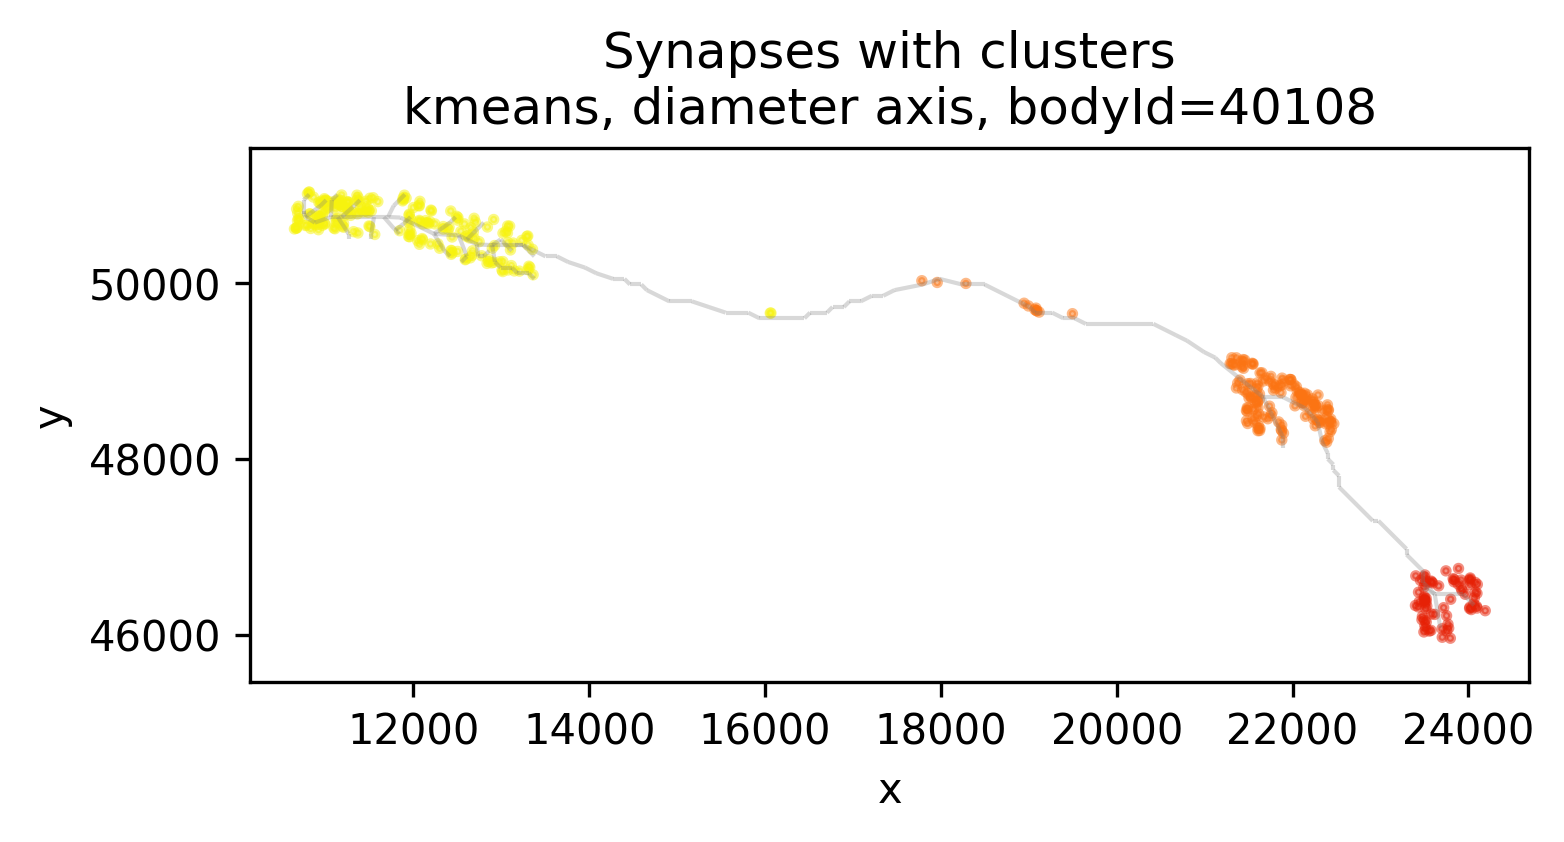

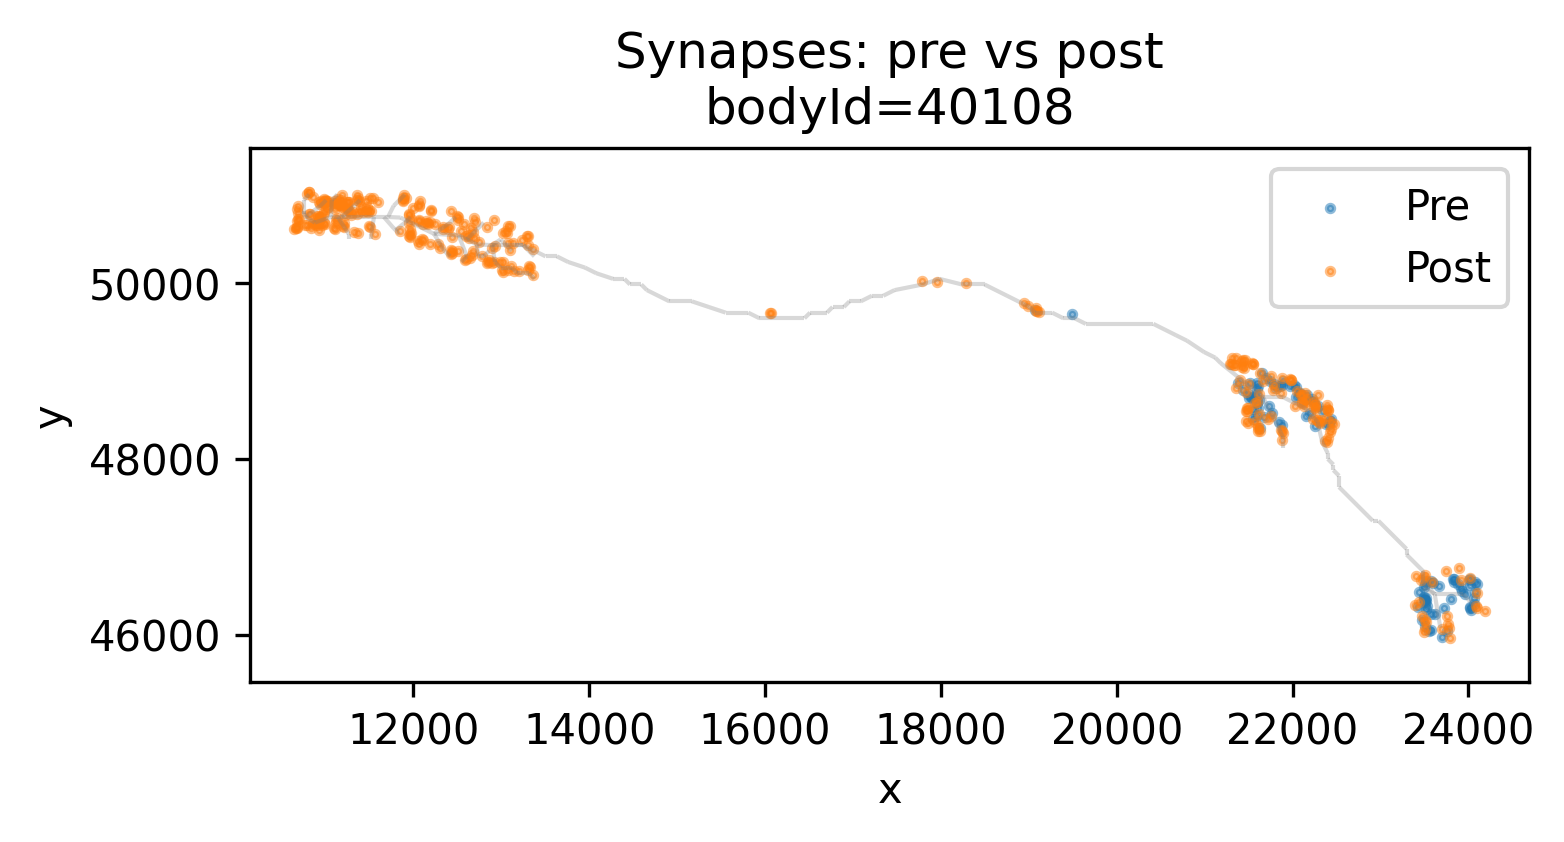

,structure,cluster,d_soma_path,d_soma_euclid,traj_coord,soma_source
162,post,1,NaN,NaN,8605.467882,none
163,post,1,NaN,NaN,8333.938878,none
164,post,1,NaN,NaN,3394.063124,none
165,post,1,NaN,NaN,8807.853652,none
166,post,2,NaN,NaN,14659.630589,none


In [85]:
bodyID = 40108         # a Tm1
clusters = 3

cluster_colors = {
    0: "#E62106",
    1: "#fb7413",
    2: "#F7F30E",
    3: "#04c518",
    4: "#1FEFFA",
    5: "#4b3da5",
}

# Mi1 example, uncomment to use instead:
# bodyID = 34300
# clusters = 4
# cluster_colors = {0: "#1f1f1f", 1: "#6b6b6b", 2: "#9f9f9f", 3: "#b9b9b9"}

synrows = plot_synapse_scatterplots_for_neuron_neuprint(
    bodyID,
    client=c,
    num_clusters=clusters,
    clustering_method="kmeans",     # "projected_gap" or "kmeans"
    gap_min_cluster_size=15,
    gap_min_gap_frac_of_median=1.5,
    cluster_order_metric="auto",
    cluster_colors=cluster_colors,
    alpha=0.5,
    skeleton_alpha=0.3,
    skeleton_linewidth=1,
    pad=500,
)

cols = ["structure", "cluster", "d_soma_path", "d_soma_euclid", "traj_coord", "soma_source"]
synrows[[col for col in cols if col in synrows.columns]].head()

### A batch of neurons

In [115]:
# Use one of the lists above. Alternatives:
#   look neurons up by cell type:  neuron_ids = get_neuron_ids("Tm2", client=c, limit=100)
#   a hand-picked list:            neuron_ids = [40139, 47057, 43233, 44460, 530319, 47665, 60776]
neuron_ids = NEURON_IDS["Tm3"]

In [111]:
neuron_ids = [
    56136,
57620,
57950,
57972,
58099,
58464,
58486,
58928,
58945,
59864,
59880,
59998
]

In [116]:
from collections import Counter

print(len(neuron_ids), "ids,", len(set(neuron_ids)), "unique")
print("repeated:", [bid for bid, n in Counter(neuron_ids).items() if n > 1])

100 ids, 100 unique
repeated: []


Found somaLocation for 12 of 12 neurons.
Plotting 56136 ...


  0%|          | 0/1 [00:00<?, ?it/s]

[56136] soma anchored at skeleton node 1 (scale 1, 50 from nearest node), axis=soma_oriented
[56136] clustering method used: projected_gap
[56136] cluster counts: {0: 353, 1: 158, 2: 100, 3: 101, 4: 78, 5: 38}
[56136] cluster order by d_soma_path:
             final_cluster_label   order_value  traj_coord_norm_median  \
cluster_raw                                                              
0                              0   3983.058390                0.114566   
1                              1   8727.017871                0.243312   
2                              2  13276.982361                0.387698   
3                              3  14399.964989                0.445894   
4                              4  22137.752448                0.915258   
5                              5  27869.186702                0.983630   

             x_median  y_median  n_synapses  
cluster_raw                                  
0              8234.0   40355.0         353  
1             10476.0

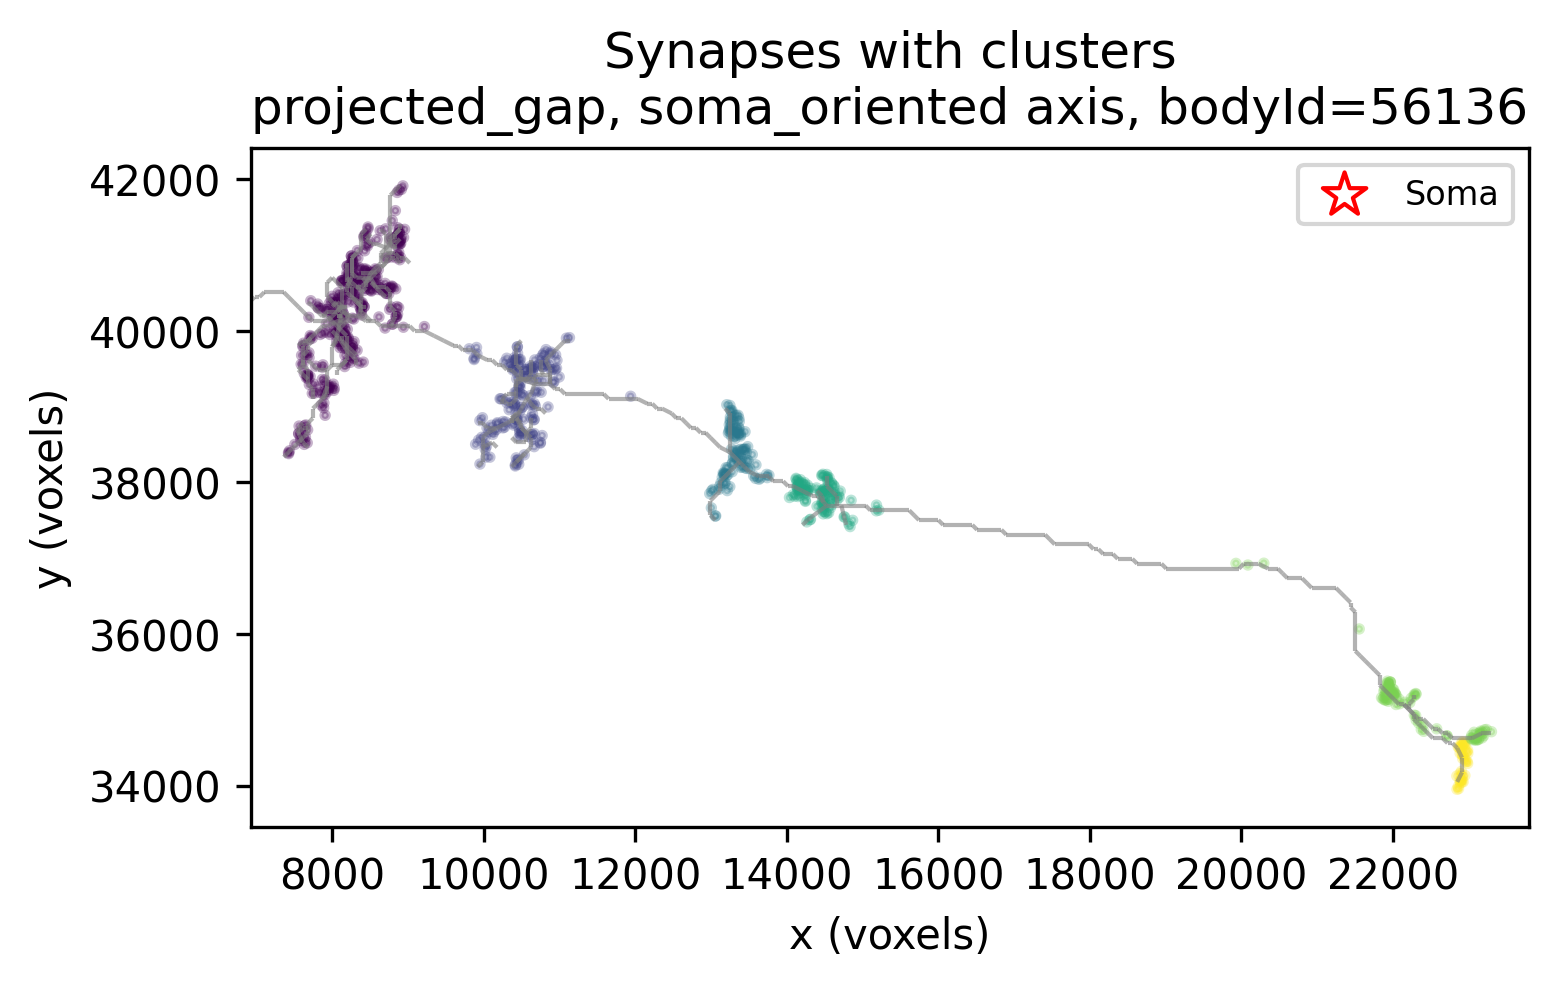

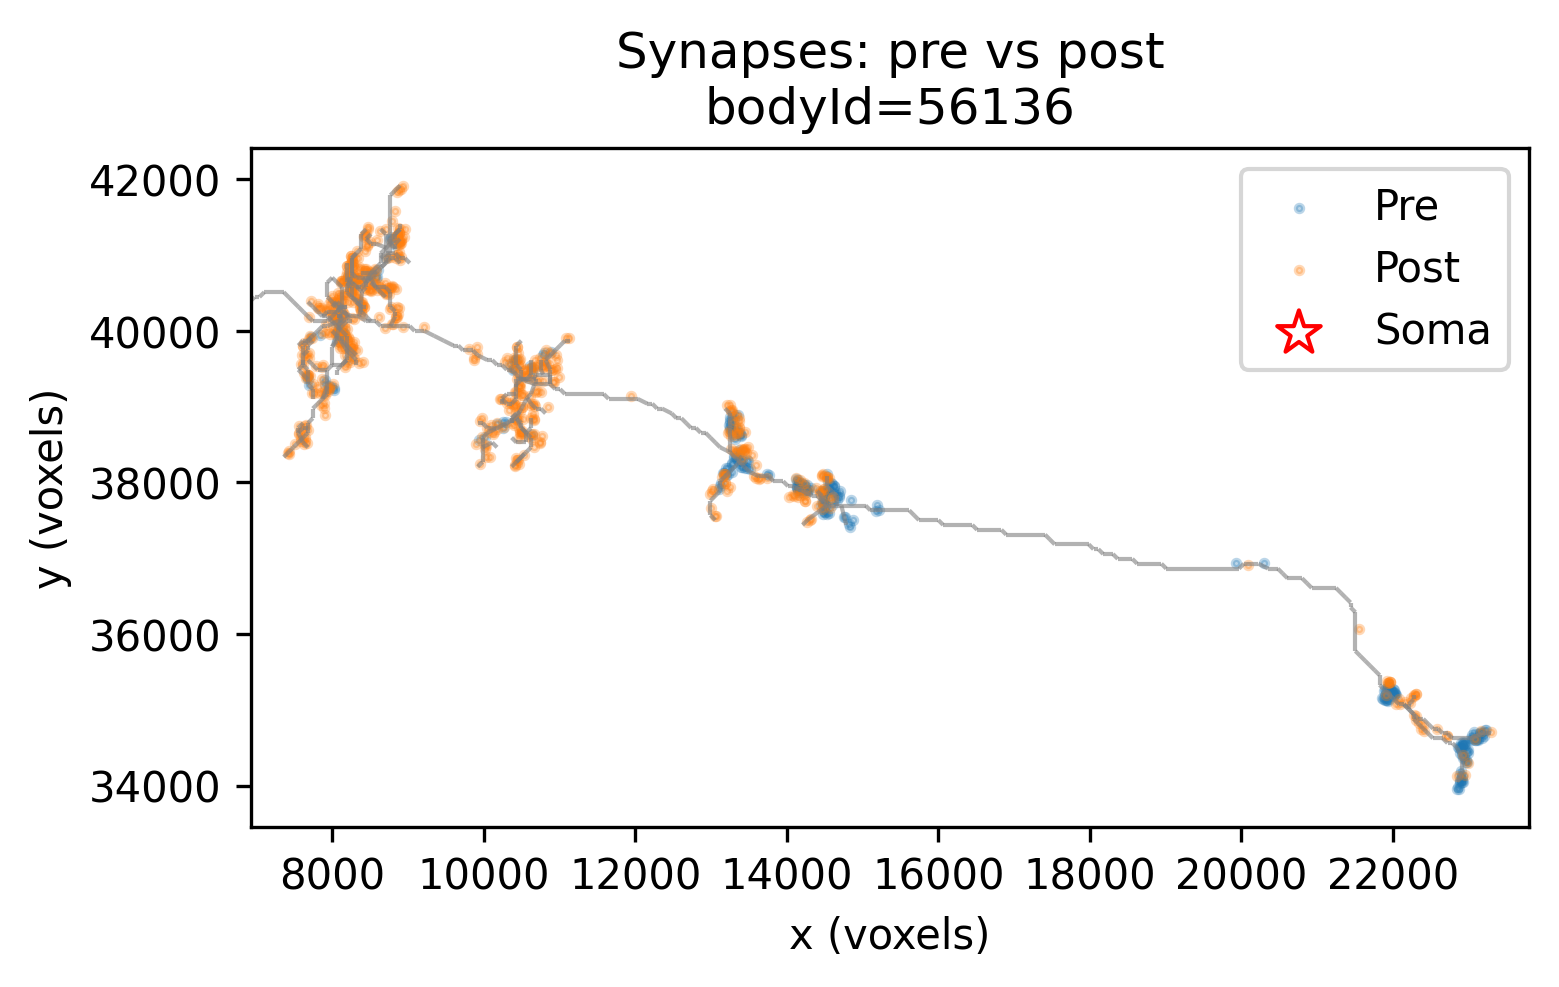

Plotting 57620 ...


  0%|          | 0/1 [00:00<?, ?it/s]

[57620] soma anchored at skeleton node 1 (scale 1, 80 from nearest node), axis=soma_oriented
[57620] clustering method used: projected_gap
[57620] cluster counts: {0: 316, 1: 142, 2: 178, 3: 15, 4: 57, 5: 52}
[57620] cluster order by d_soma_path:
             final_cluster_label   order_value  traj_coord_norm_median  \
cluster_raw                                                              
0                              0   5539.176790                0.081994   
1                              1   8785.374598                0.207454   
2                              2  12681.264043                0.372499   
3                              3  18628.721935                0.588605   
4                              4  23186.226995                0.881383   
5                              5  27994.901314                0.967978   

             x_median  y_median  n_synapses  
cluster_raw                                  
0             10330.5   44040.5         316  
1             12422.0 

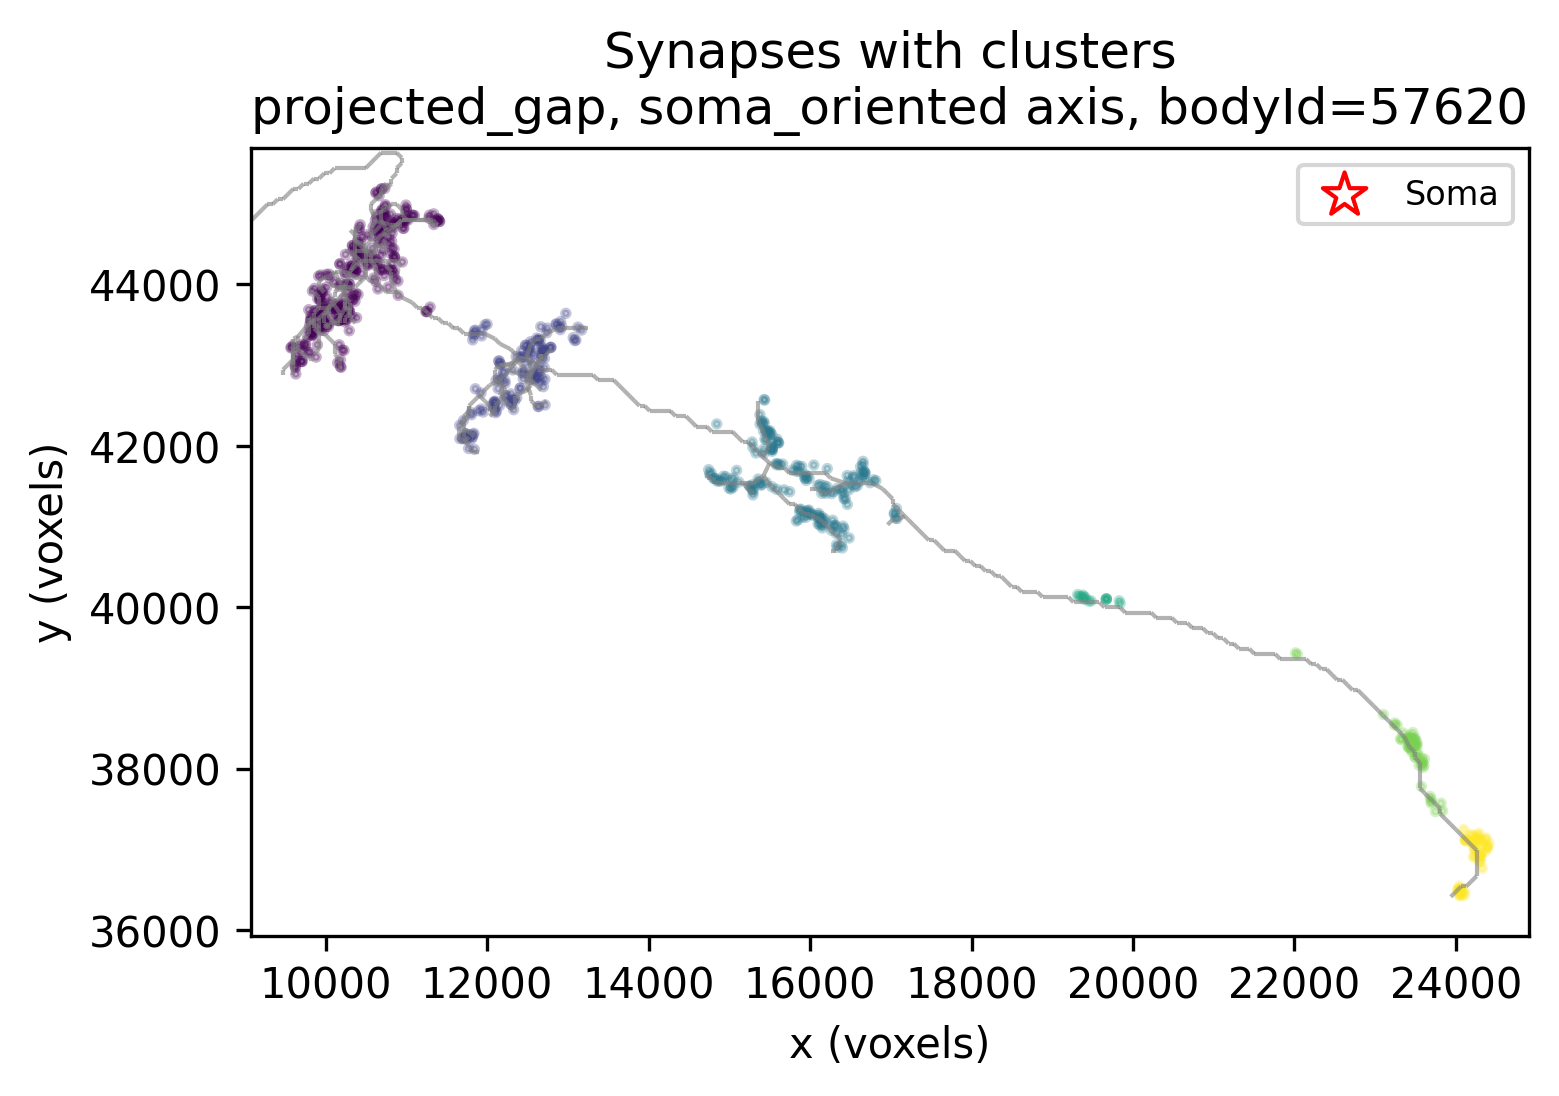

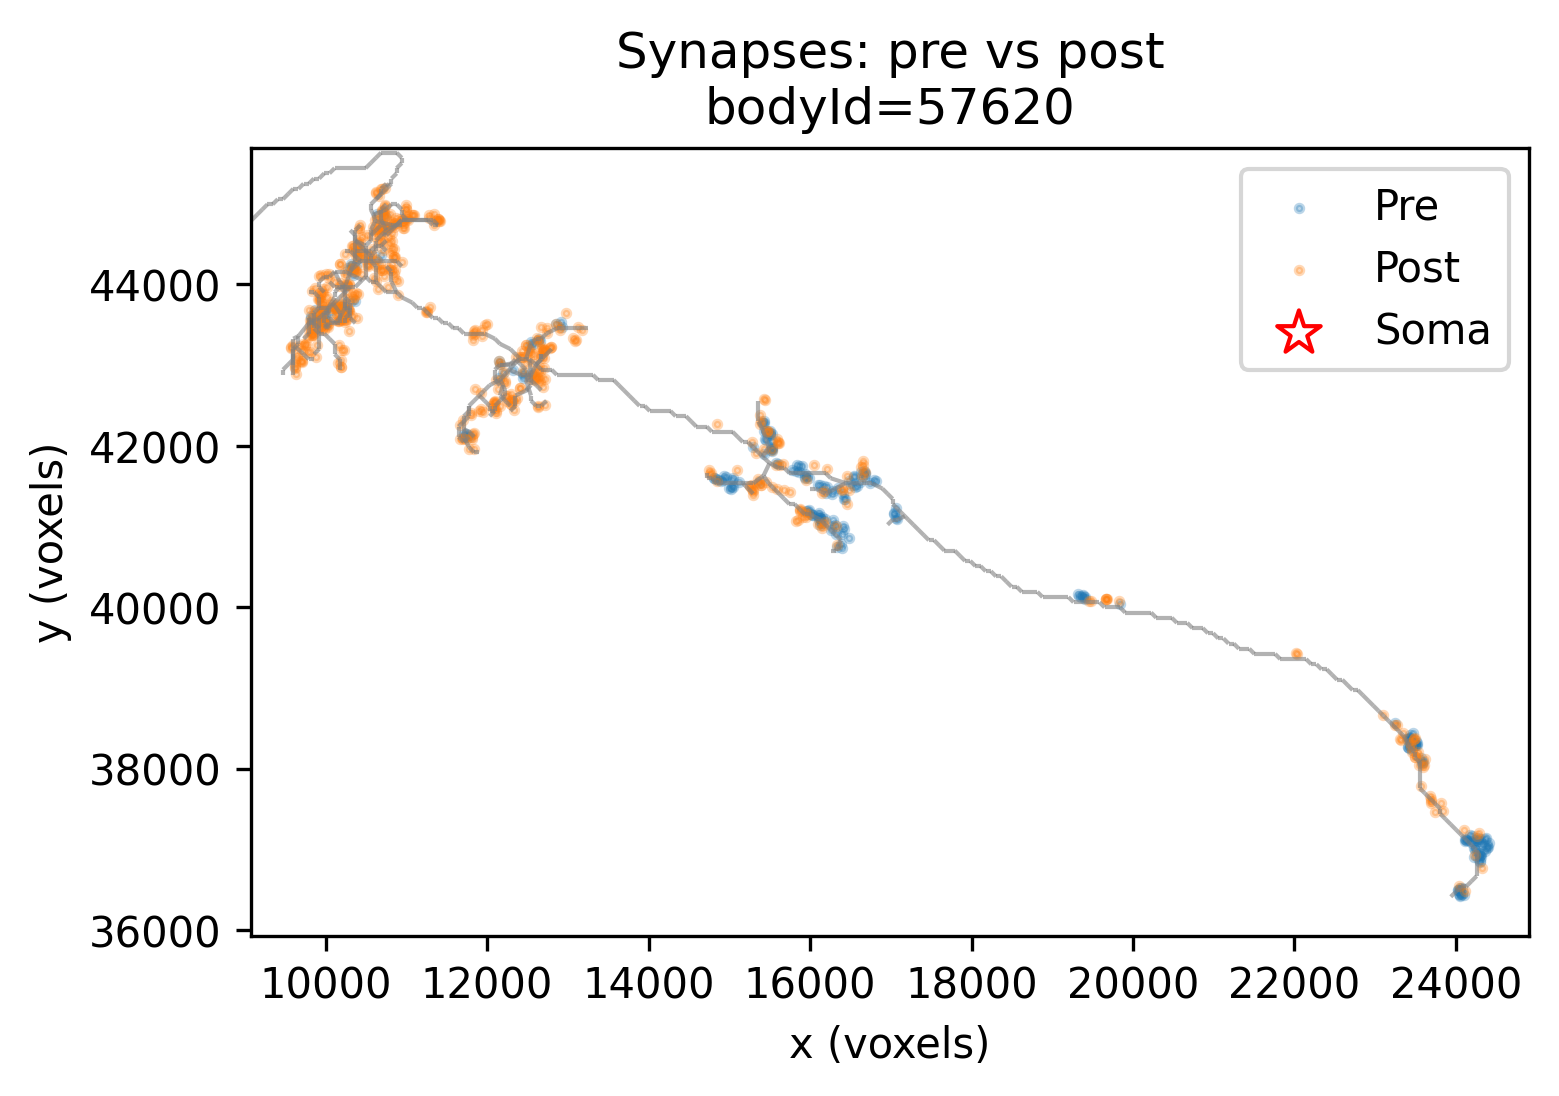

Plotting 57950 ...


  0%|          | 0/1 [00:00<?, ?it/s]

[57950] soma anchored at skeleton node 1 (scale 1, 36 from nearest node), axis=soma_oriented
[57950] clustering method used: projected_gap
[57950] cluster counts: {0: 269, 1: 27, 2: 213, 3: 204, 4: 75, 5: 19}
[57950] cluster order by d_soma_path:
             final_cluster_label   order_value  traj_coord_norm_median  \
cluster_raw                                                              
1                              0   4854.234881                0.079560   
0                              1   6244.140302                0.029388   
2                              2   6940.400783                0.203607   
3                              3  11547.795593                0.395554   
4                              4  17457.652023                0.882426   
5                              5  26913.532444                0.989024   

             x_median  y_median  n_synapses  
cluster_raw                                  
1              6897.0   36565.0         269  
0              7201.0 

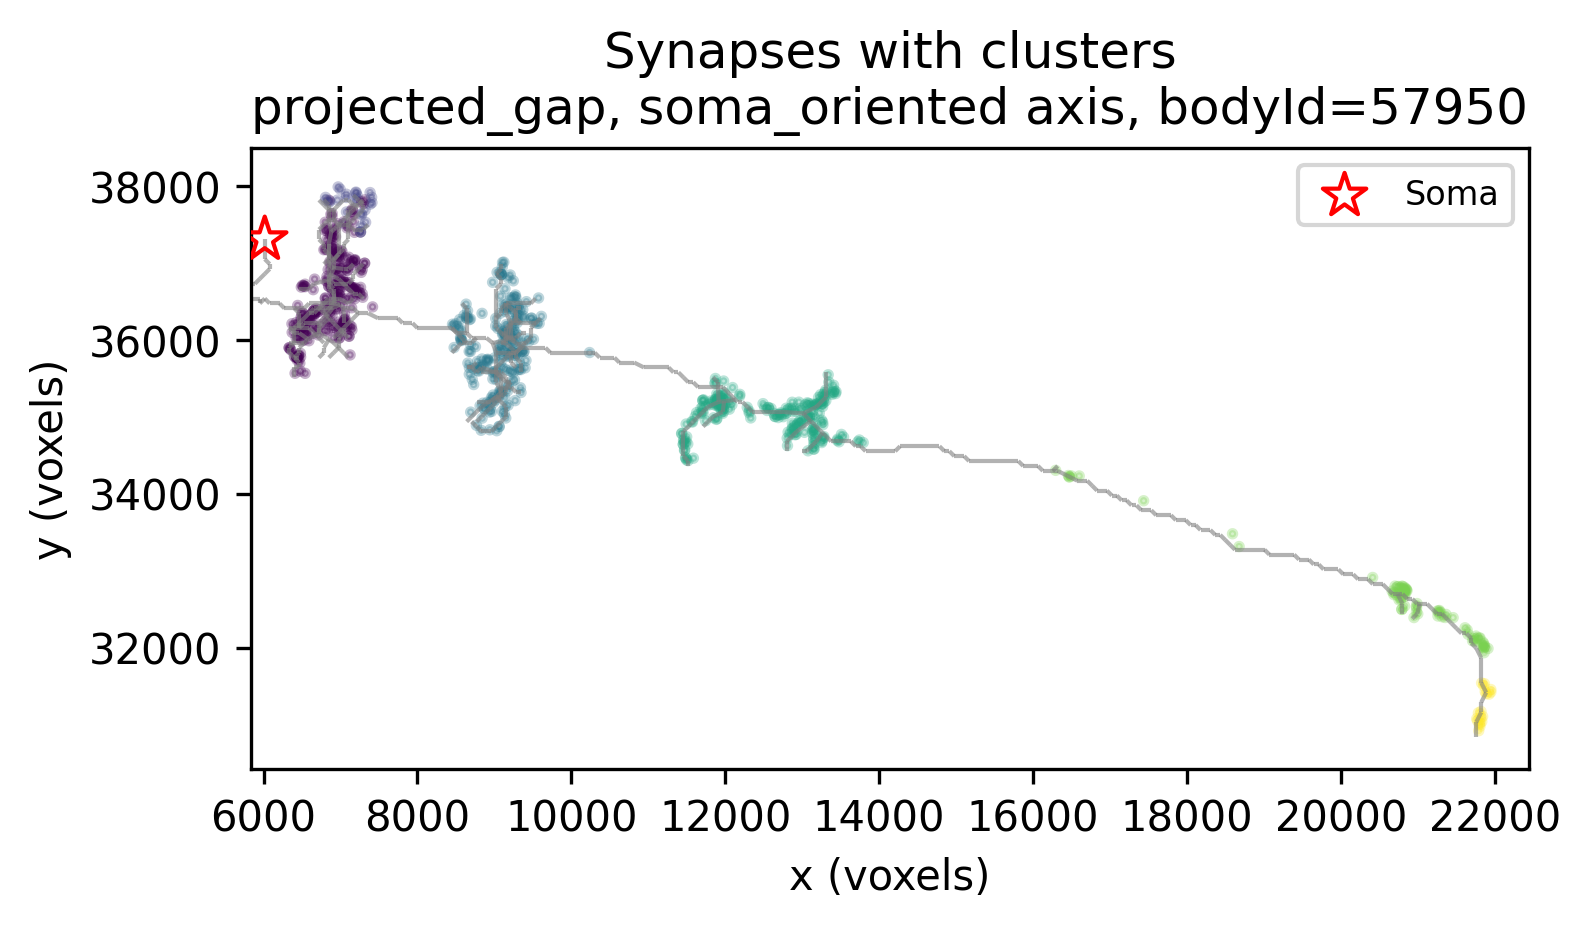

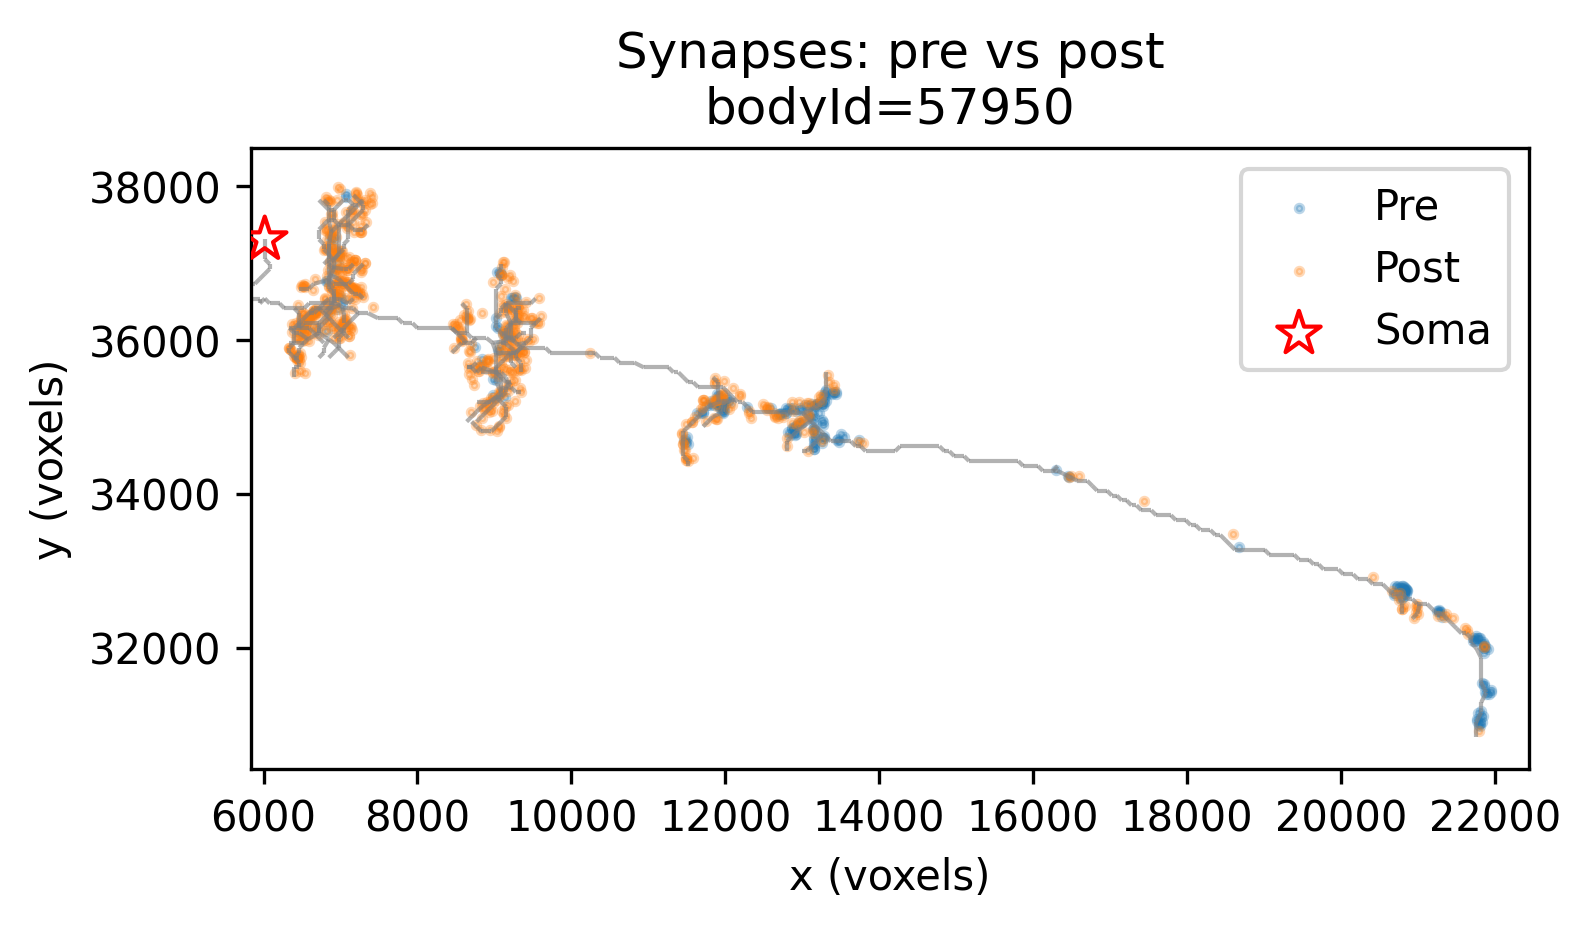

Plotting 57972 ...


  0%|          | 0/1 [00:00<?, ?it/s]

[57972] soma anchored at skeleton node 2 (scale 1, 119 from nearest node), axis=soma_oriented
[57972] clustering method used: projected_gap
[57972] cluster counts: {0: 407, 1: 94, 2: 189, 3: 23, 4: 42, 5: 46}
[57972] cluster order by d_soma_path:
             final_cluster_label   order_value  traj_coord_norm_median  \
cluster_raw                                                              
0                              0   3569.745293                0.104654   
1                              1   7325.591153                0.219856   
2                              2  11878.871553                0.382250   
3                              3  16030.567810                0.599076   
4                              4  24213.097904                0.904268   
5                              5  26507.861264                0.984270   

             x_median  y_median  n_synapses  
cluster_raw                                  
0             11505.0   45802.0         407  
1             13861.5 

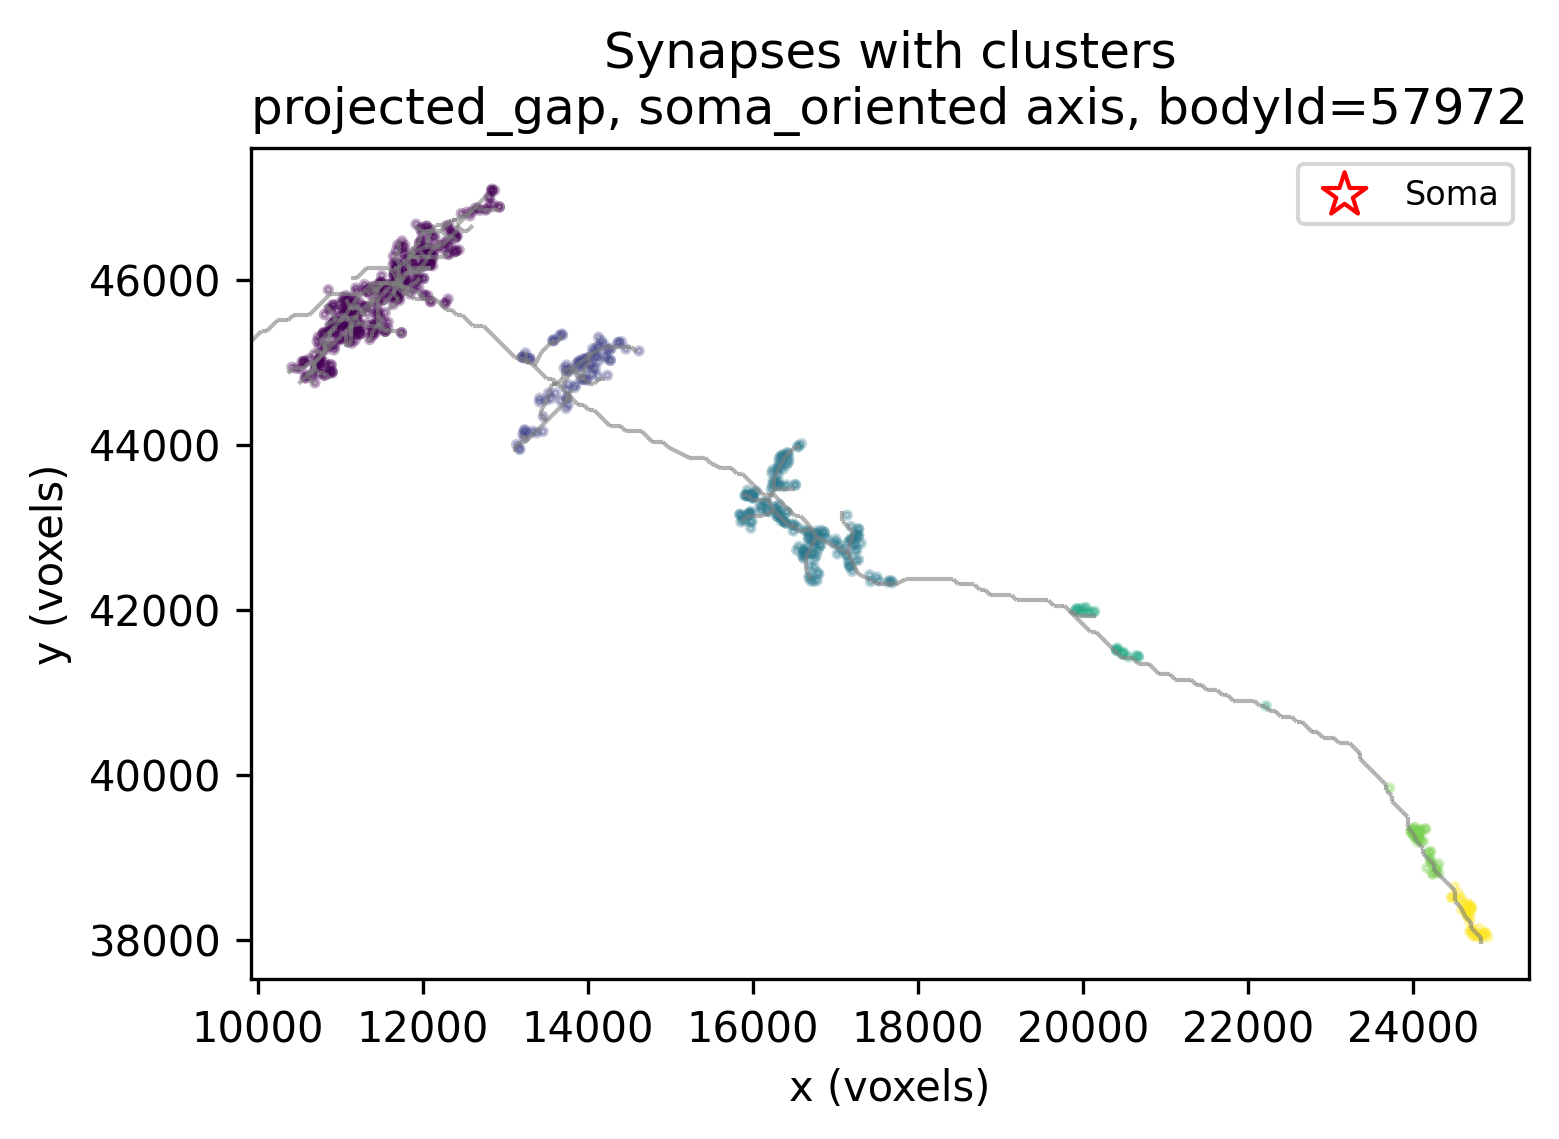

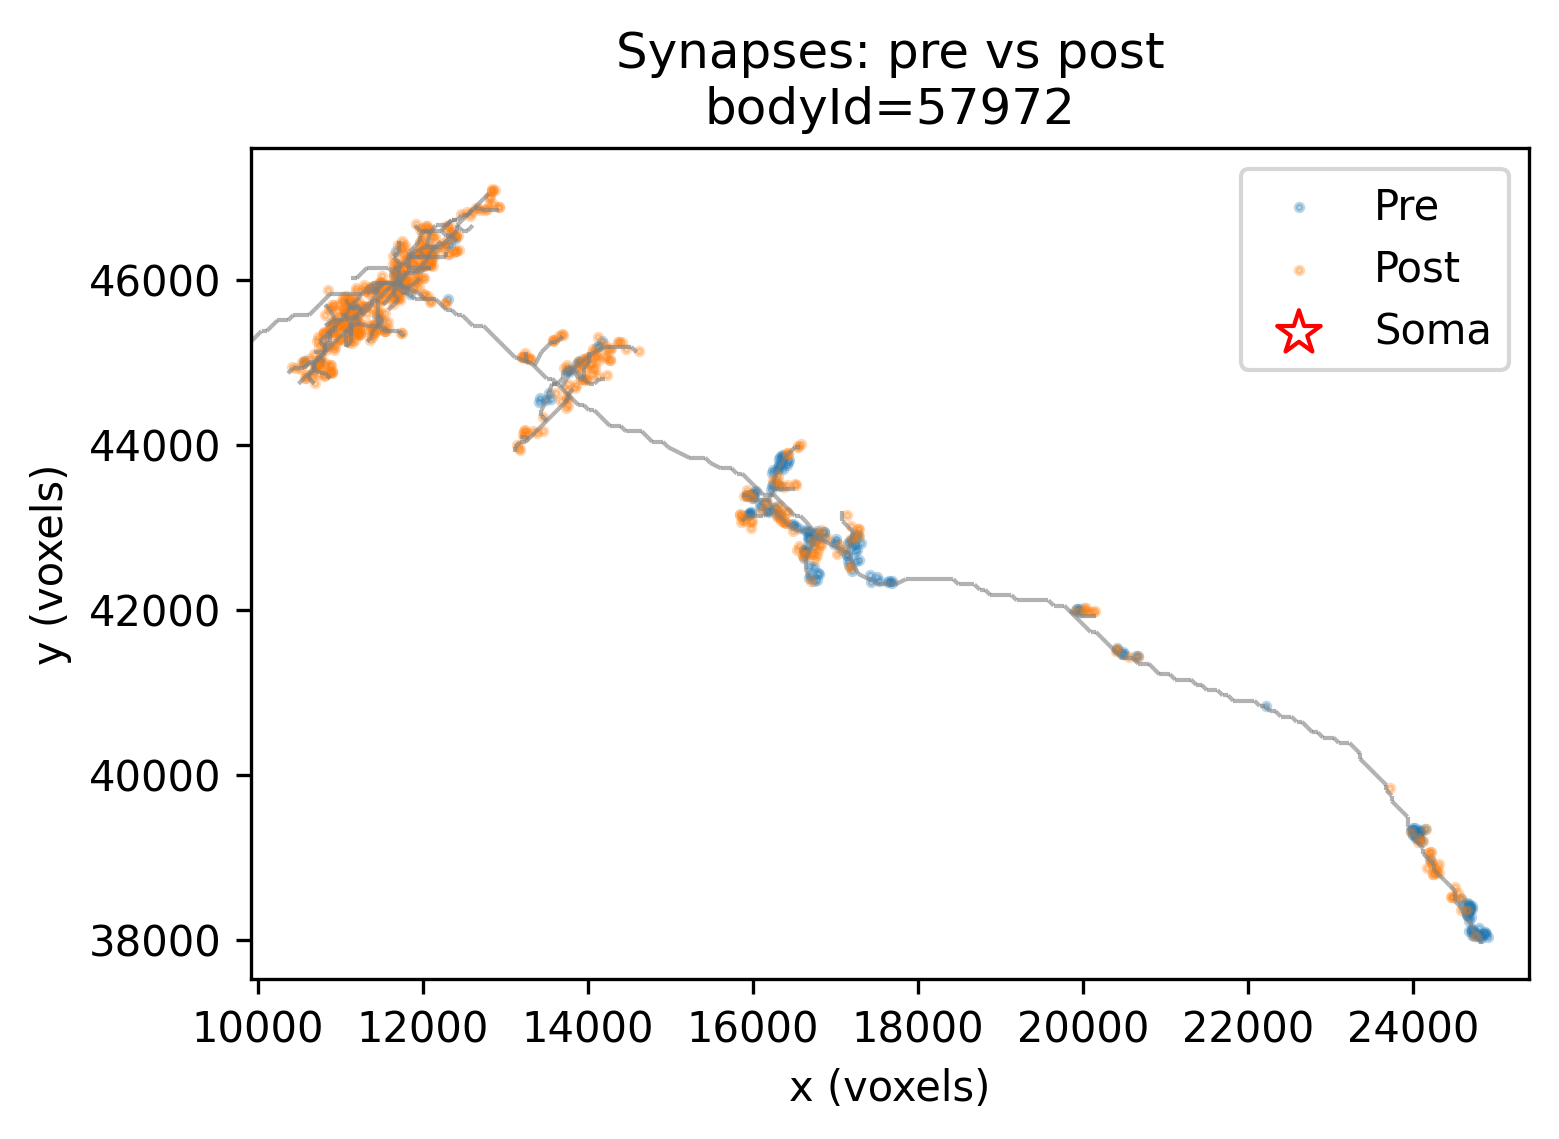

Plotting 58099 ...


  0%|          | 0/1 [00:00<?, ?it/s]

[58099] soma anchored at skeleton node 1 (scale 1, 50 from nearest node), axis=soma_oriented
[58099] clustering method used: projected_gap
[58099] cluster counts: {0: 273, 1: 15, 2: 171, 3: 196, 4: 52, 5: 48}
[58099] cluster order by d_soma_path:
             final_cluster_label   order_value  traj_coord_norm_median  \
cluster_raw                                                              
1                              0   2491.140767                0.091395   
0                              1   4394.628232                0.016211   
2                              2   5284.805251                0.214873   
3                              3   8688.812324                0.359599   
4                              4  22653.042394                0.905162   
5                              5  25209.676610                0.970360   

             x_median  y_median  n_synapses  
cluster_raw                                  
1              7790.0   39900.0         273  
0              7050.0 

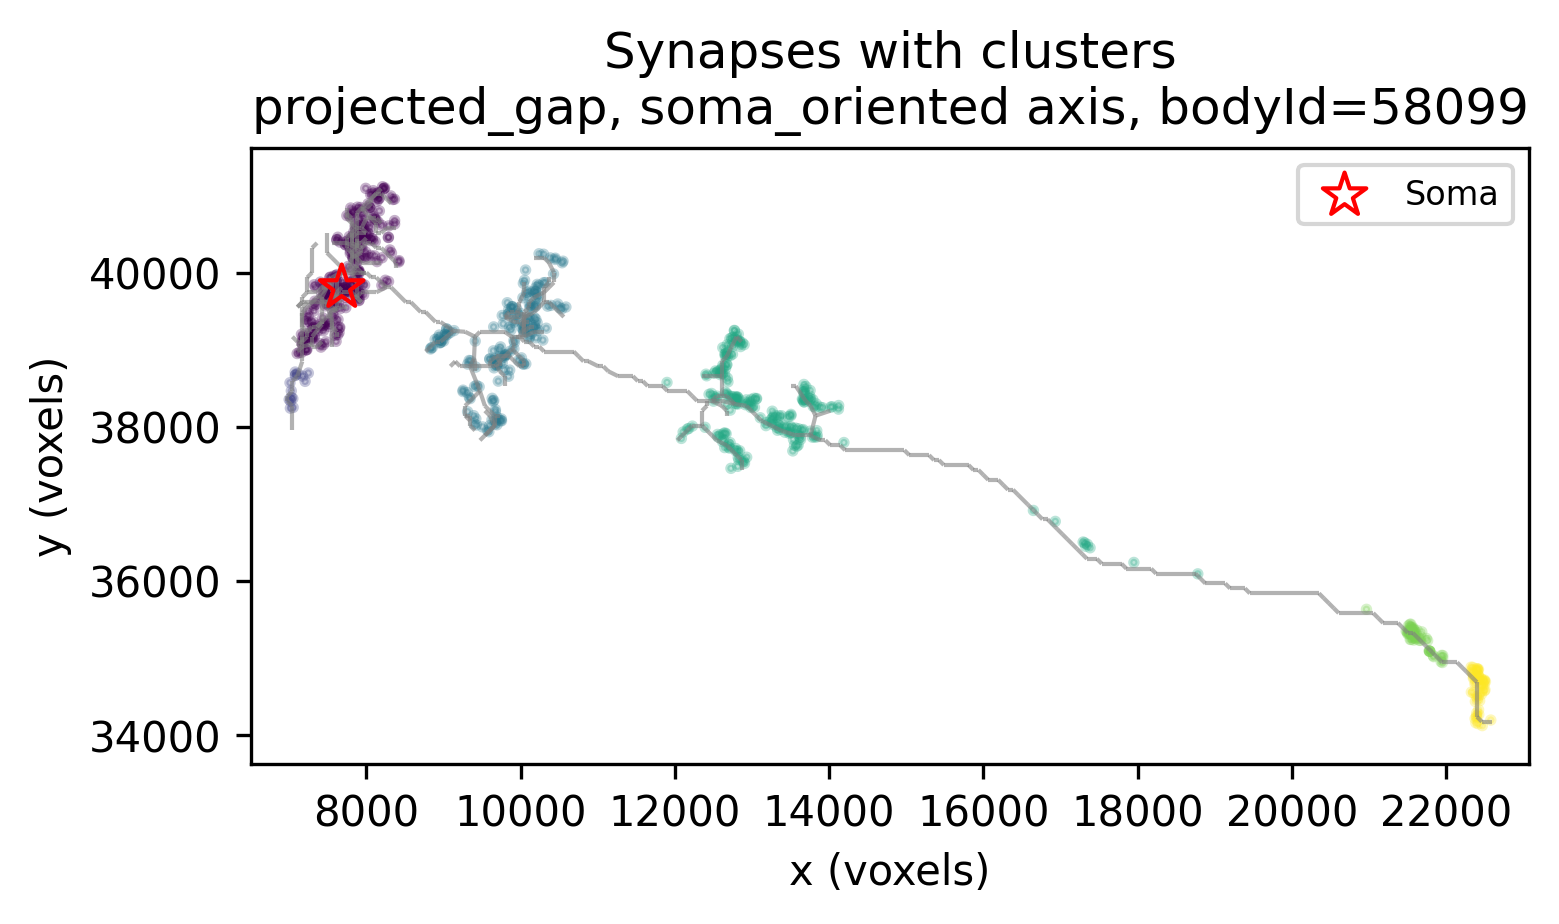

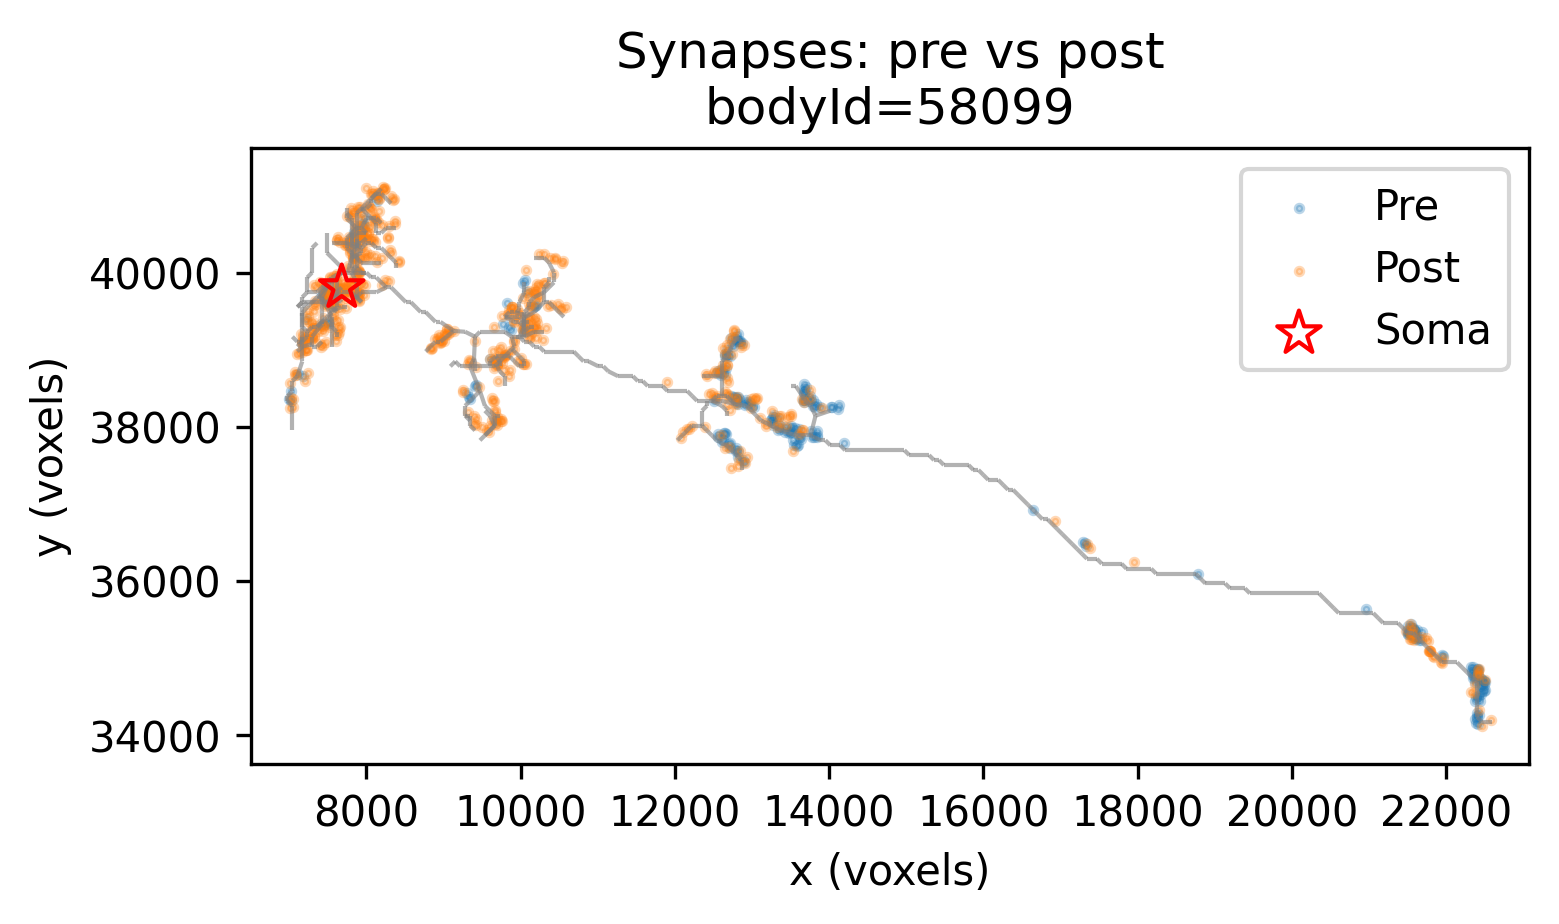

Plotting 58464 ...


  0%|          | 0/1 [00:00<?, ?it/s]

[58464] soma anchored at skeleton node 1 (scale 1, 68 from nearest node), axis=soma_oriented
[58464] WARNING: cluster labels are not monotonic in distance from the soma under cluster_order_metric='d_soma_path' (medians [7879, 7741, 10812, 14348, 25446, 27417]). This usually means the A-B axis runs tip to tip past the soma. Use cluster_order_metric='d_soma_path' for soma-referenced labels.
[58464] clustering method used: projected_gap
[58464] cluster counts: {0: 187, 1: 122, 2: 124, 3: 184, 4: 46, 5: 46}
[58464] cluster order by d_soma_path:
             final_cluster_label   order_value  traj_coord_norm_median  \
cluster_raw                                                              
1                              0   6105.305087                0.118119   
0                              1   6902.322730                0.061220   
2                              2   9218.483789                0.241299   
3                              3  12987.025147                0.403058   
4        

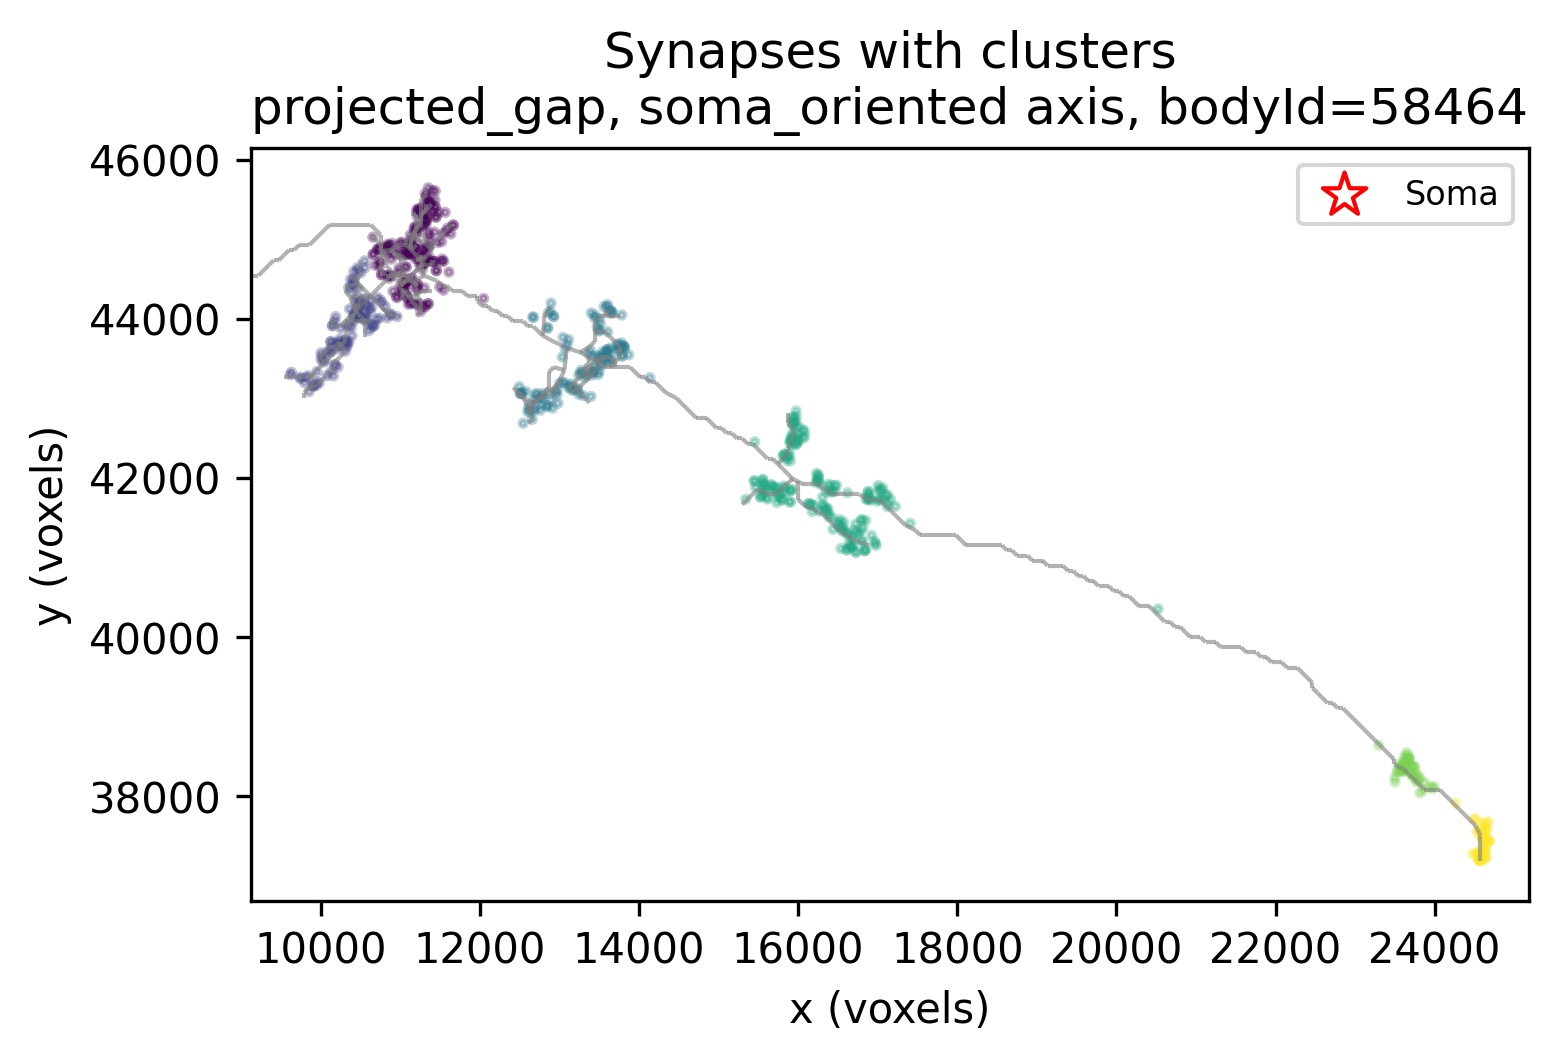

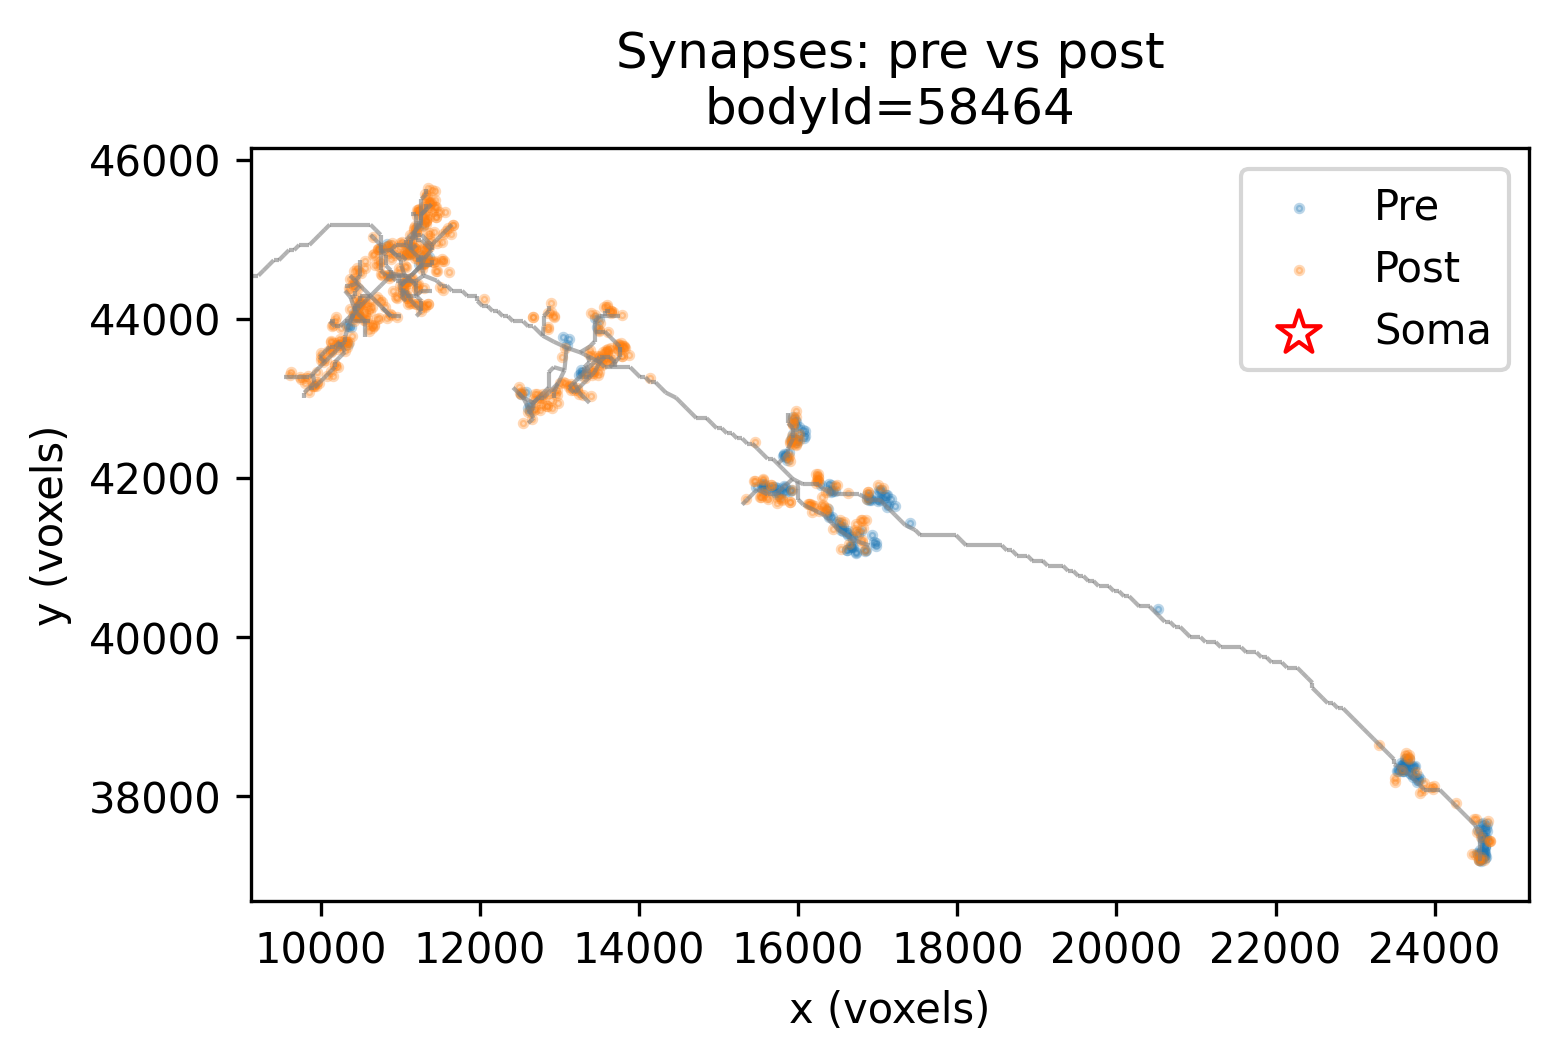

Plotting 58486 ...


  0%|          | 0/1 [00:00<?, ?it/s]

[58486] soma anchored at skeleton node 1 (scale 1, 154 from nearest node), axis=soma_oriented
[58486] clustering method used: projected_gap
[58486] cluster counts: {0: 295, 1: 17, 2: 138, 3: 179, 4: 38, 5: 38}
[58486] cluster order by d_soma_path:
             final_cluster_label   order_value  traj_coord_norm_median  \
cluster_raw                                                              
0                              0   8070.619402                0.090719   
1                              1  10952.357937                0.208544   
2                              2  11287.466287                0.250981   
3                              3  15214.006003                0.476404   
4                              4  24951.647037                0.885038   
5                              5  26948.371725                0.978585   

             x_median  y_median  n_synapses  
cluster_raw                                  
0             13994.0   46555.0         295  
1             15700.0

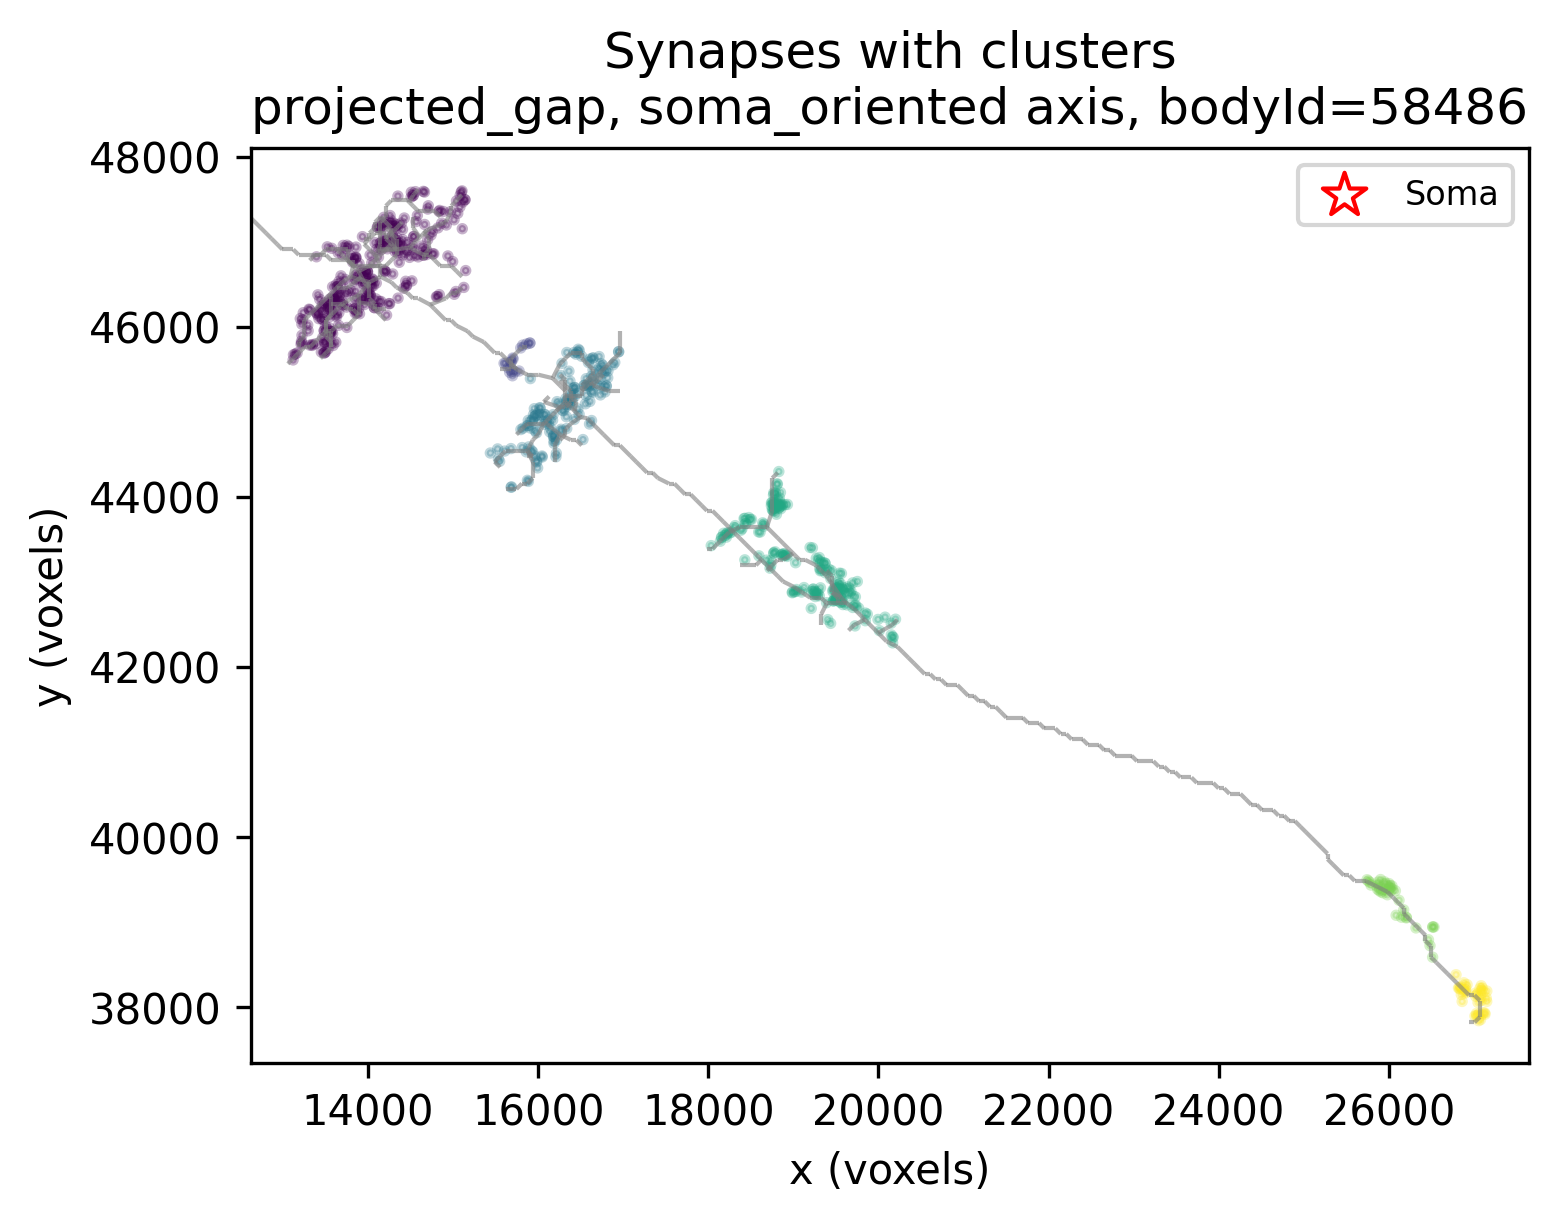

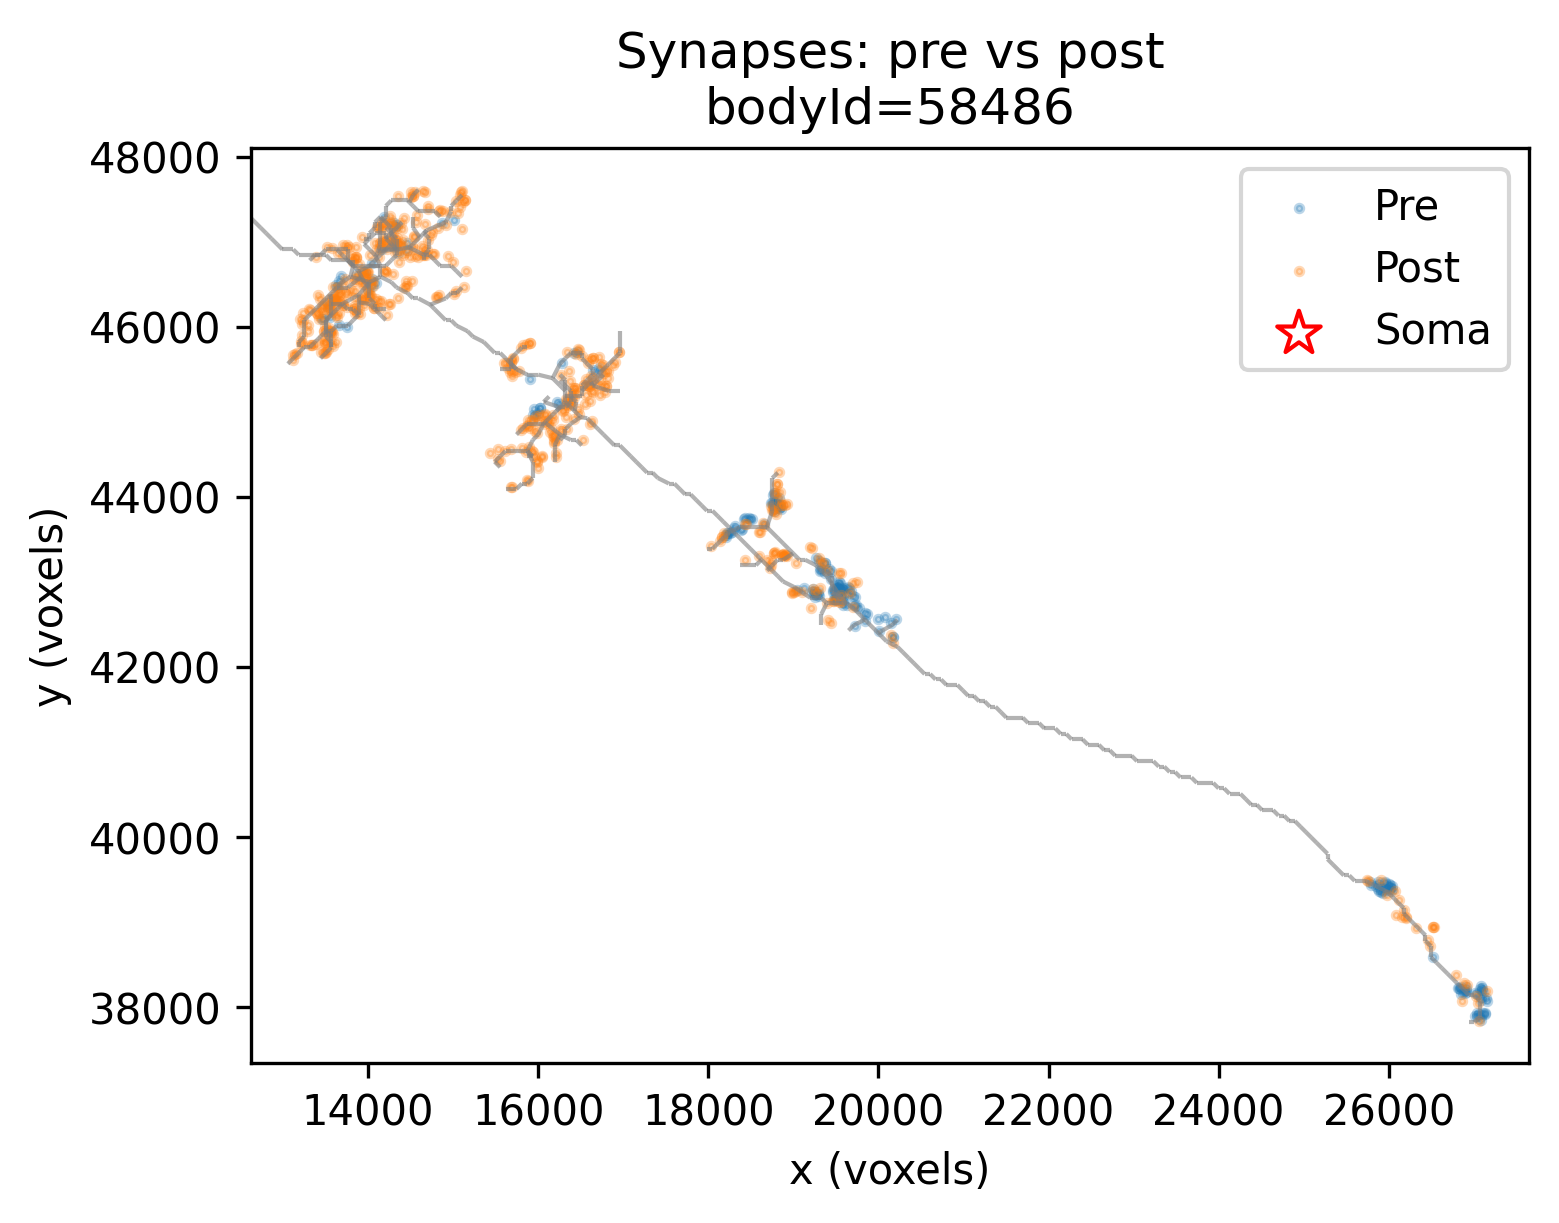

Plotting 58928 ...


  0%|          | 0/1 [00:00<?, ?it/s]

[58928] soma anchored at skeleton node 2 (scale 1, 121 from nearest node), axis=soma_oriented
[58928] clustering method used: projected_gap
[58928] cluster counts: {0: 228, 1: 57, 2: 124, 3: 158, 4: 17, 5: 115}
[58928] cluster order by d_soma_path:
             final_cluster_label   order_value  traj_coord_norm_median  \
cluster_raw                                                              
1                              0   3233.918161                0.116406   
0                              1   4722.551036                0.056213   
2                              2   5821.150449                0.227268   
3                              3  10340.971784                0.389556   
4                              4  13288.763908                0.576845   
5                              5  23620.365306                0.937154   

             x_median  y_median  n_synapses  
cluster_raw                                  
1              9339.0   42874.5         228  
0             10018.

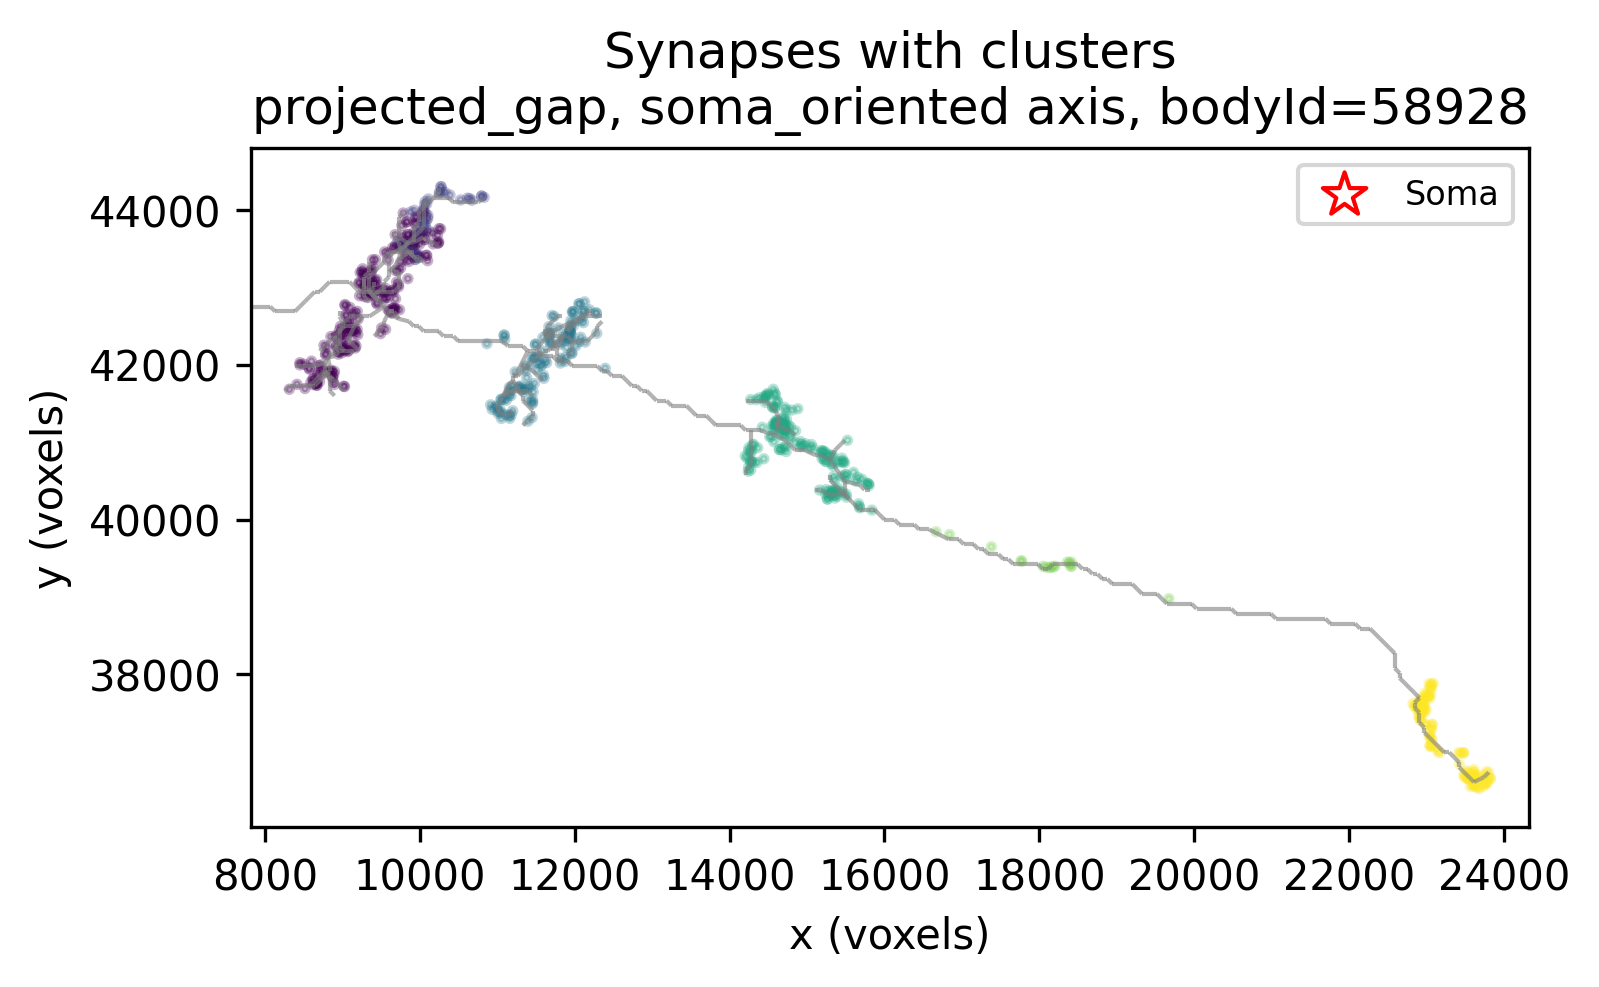

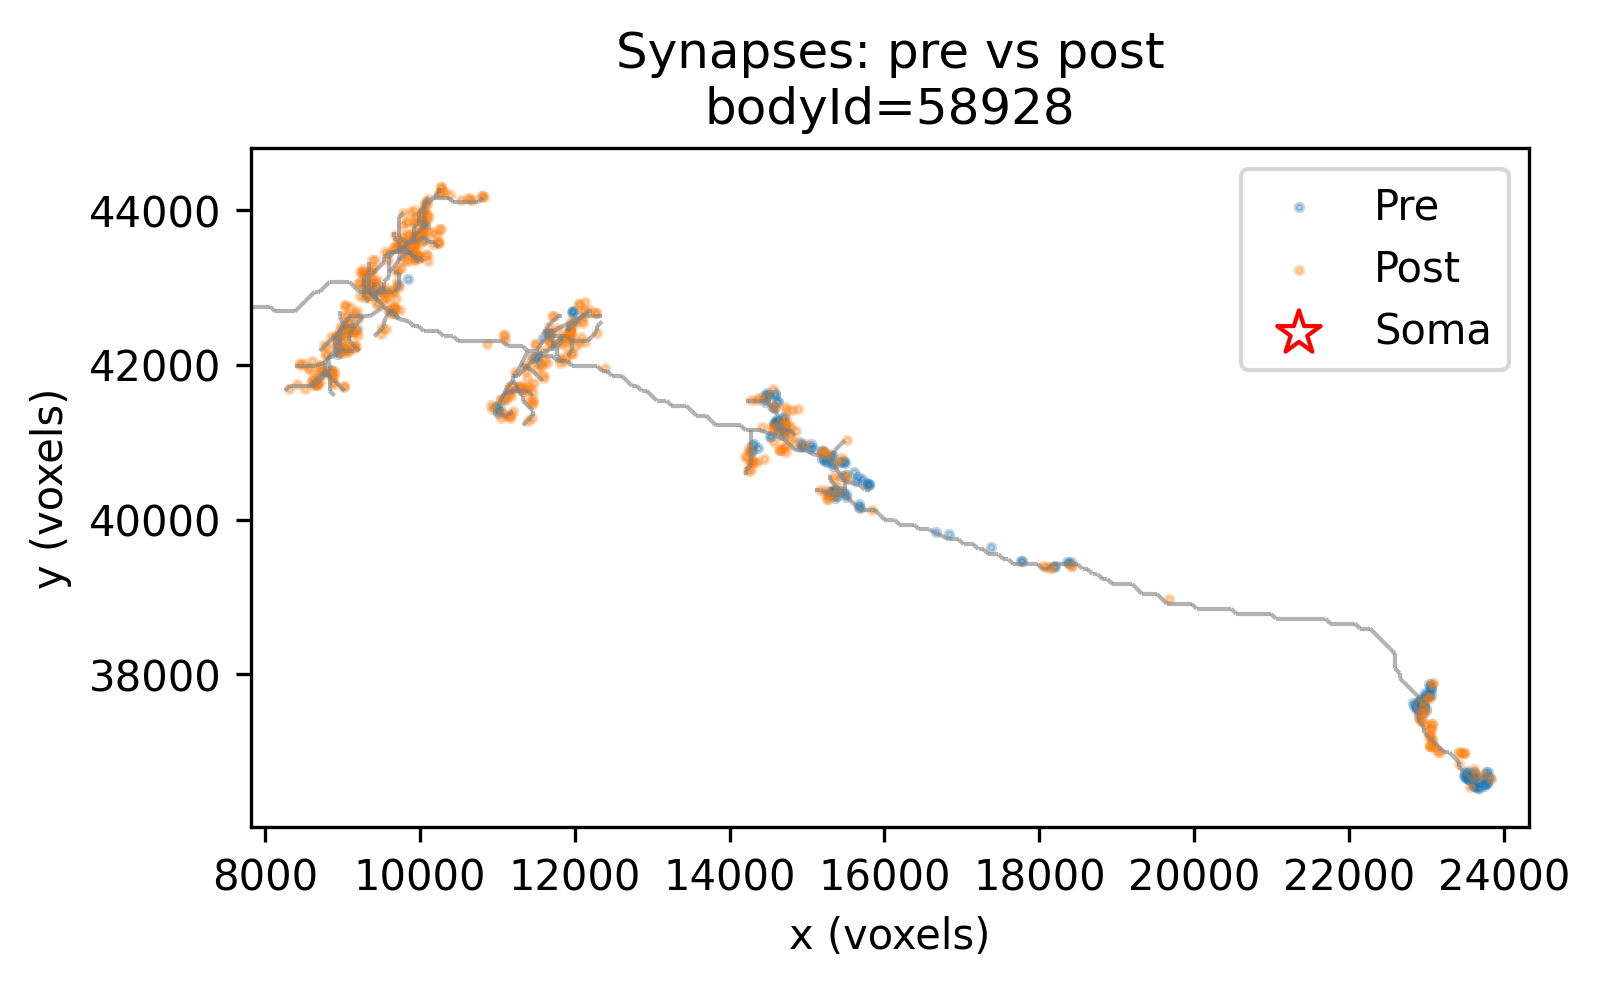

Plotting 58945 ...


  0%|          | 0/1 [00:00<?, ?it/s]

[58945] soma anchored at skeleton node 1 (scale 1, 55 from nearest node), axis=soma_oriented
[58945] clustering method used: projected_gap
[58945] cluster counts: {0: 336, 1: 149, 2: 110, 3: 98, 4: 39, 5: 36}
[58945] cluster order by d_soma_path:
             final_cluster_label   order_value  traj_coord_norm_median  \
cluster_raw                                                              
0                              0   7194.199224                0.083103   
1                              1   9035.109011                0.246230   
2                              2  14043.783930                0.438649   
3                              3  15697.895207                0.512698   
4                              4  22502.919546                0.877847   
5                              5  26609.728117                0.982042   

             x_median  y_median  n_synapses  
cluster_raw                                  
0              9271.0   38893.0         336  
1             11813.0 

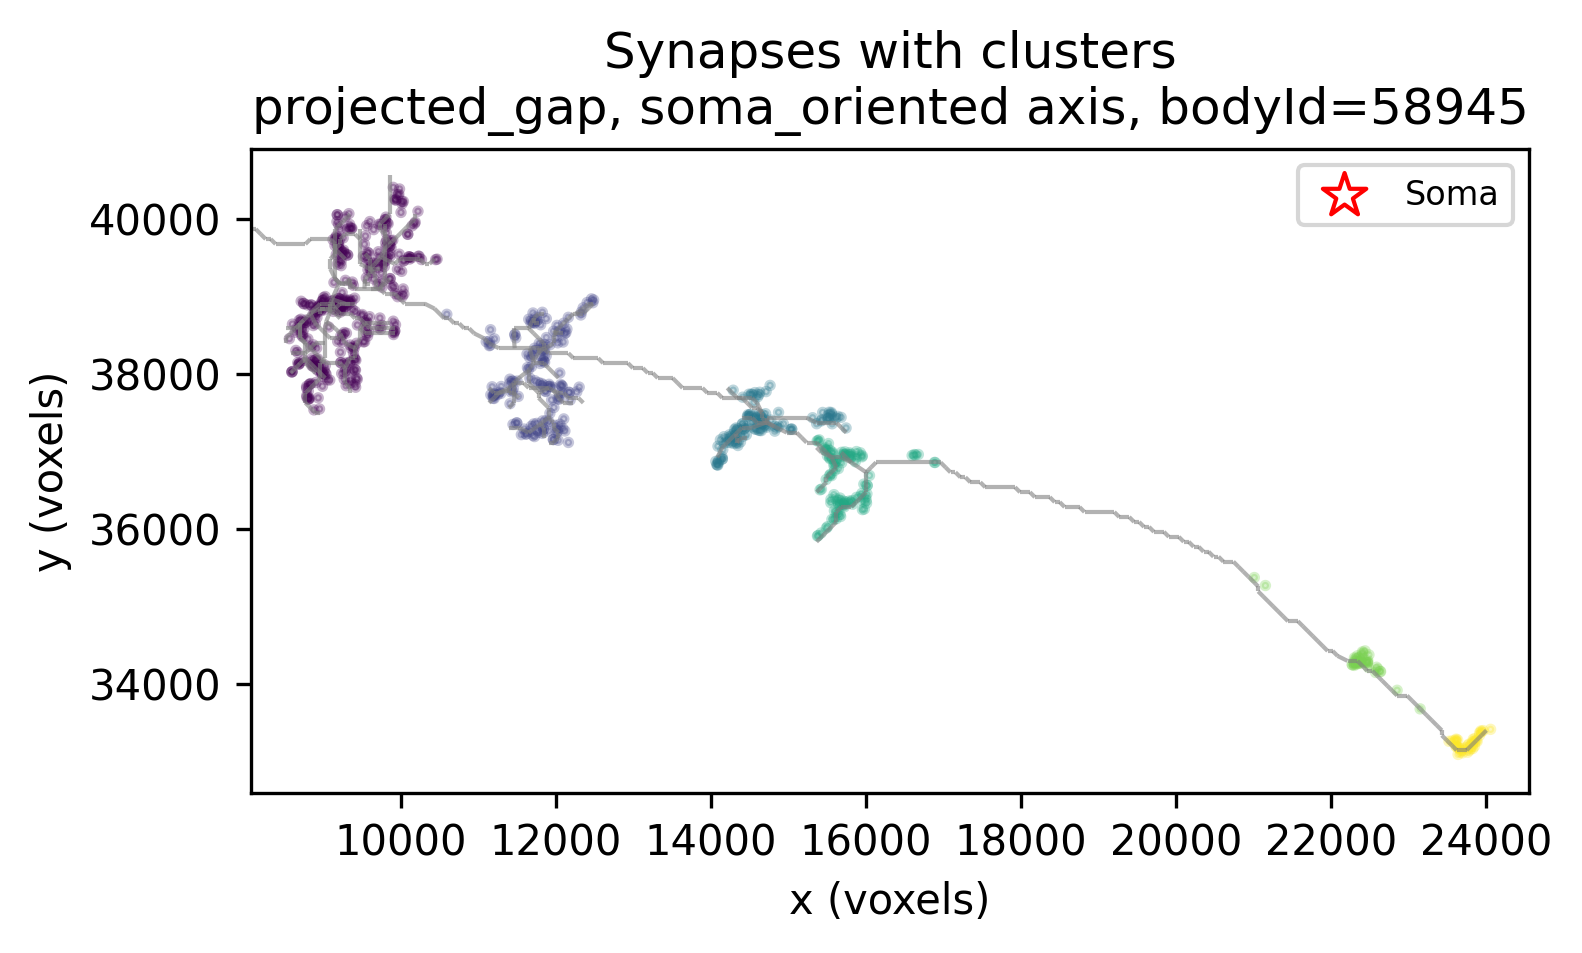

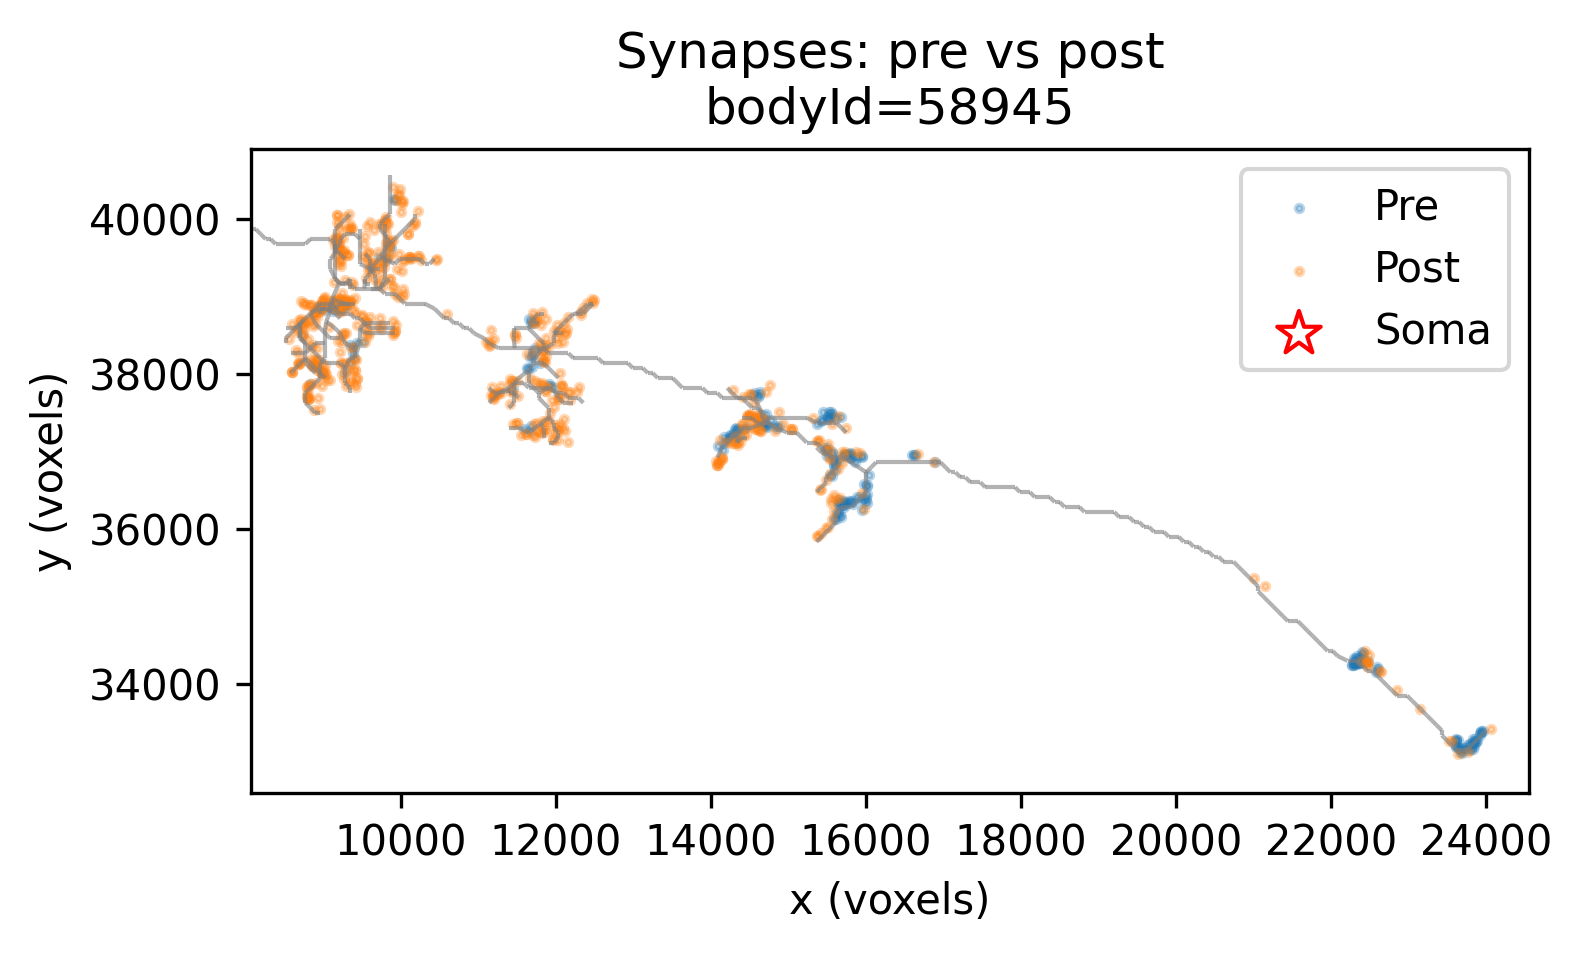

Plotting 59864 ...


  0%|          | 0/1 [00:00<?, ?it/s]

[59864] soma anchored at skeleton node 1 (scale 1, 62 from nearest node), axis=soma_oriented
[59864] clustering method used: projected_gap
[59864] cluster counts: {0: 336, 1: 204, 2: 126, 3: 55, 4: 67, 5: 39}
[59864] cluster order by d_soma_path:
             final_cluster_label   order_value  traj_coord_norm_median  \
cluster_raw                                                              
0                              0   6030.786403                0.085027   
1                              1   8255.845883                0.243379   
2                              2  13573.301715                0.411124   
3                              3  15344.924178                0.471007   
4                              4  19508.242723                0.908311   
5                              5  26367.560614                0.986544   

             x_median  y_median  n_synapses  
cluster_raw                                  
0              7724.5   36209.0         336  
1             10268.0 

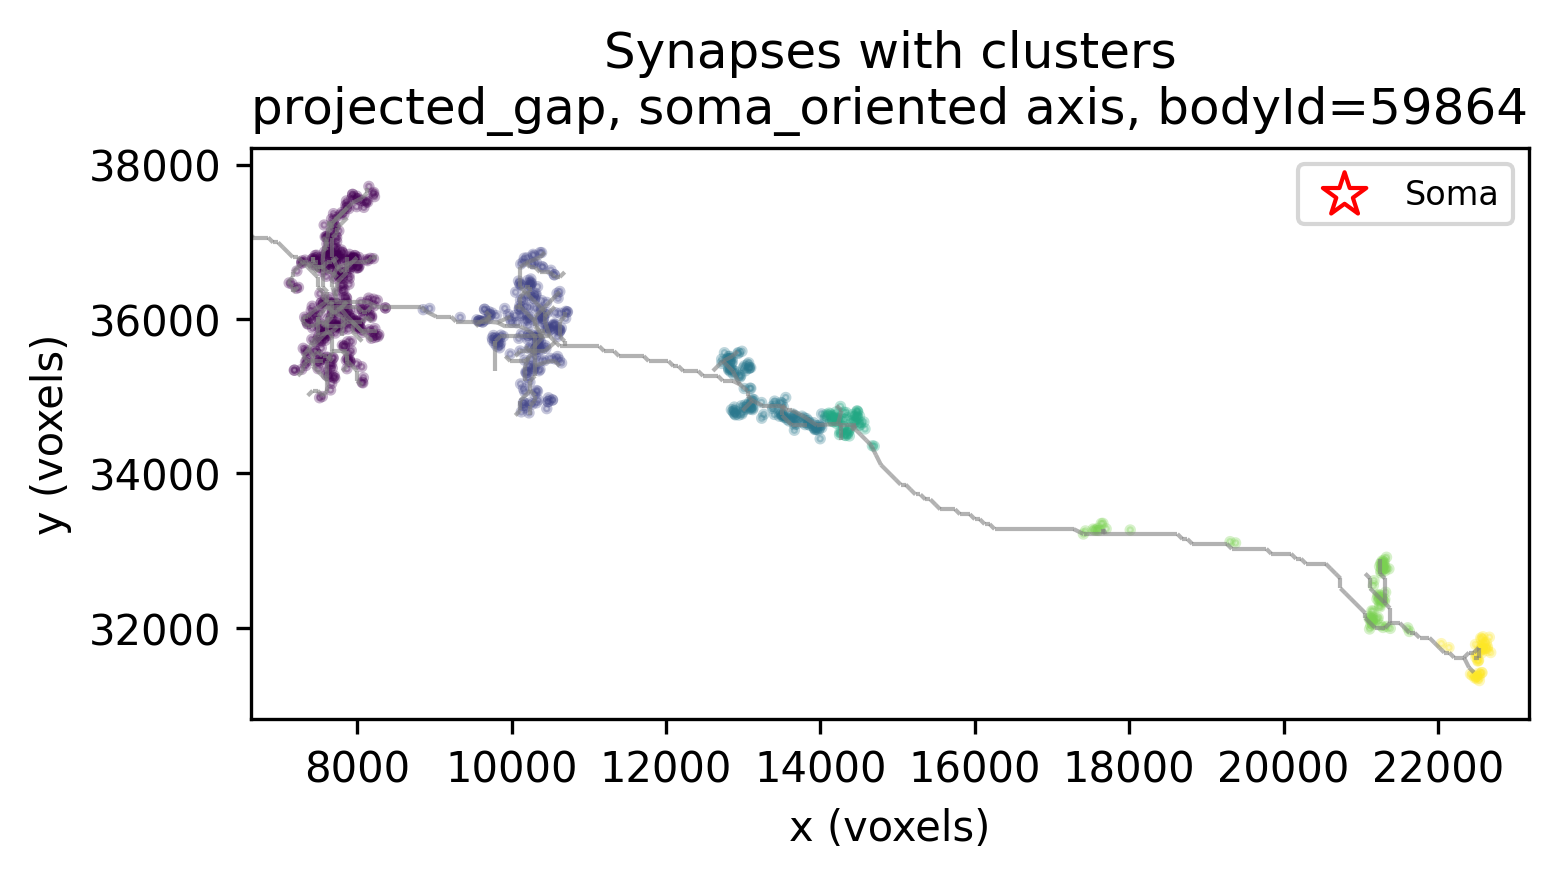

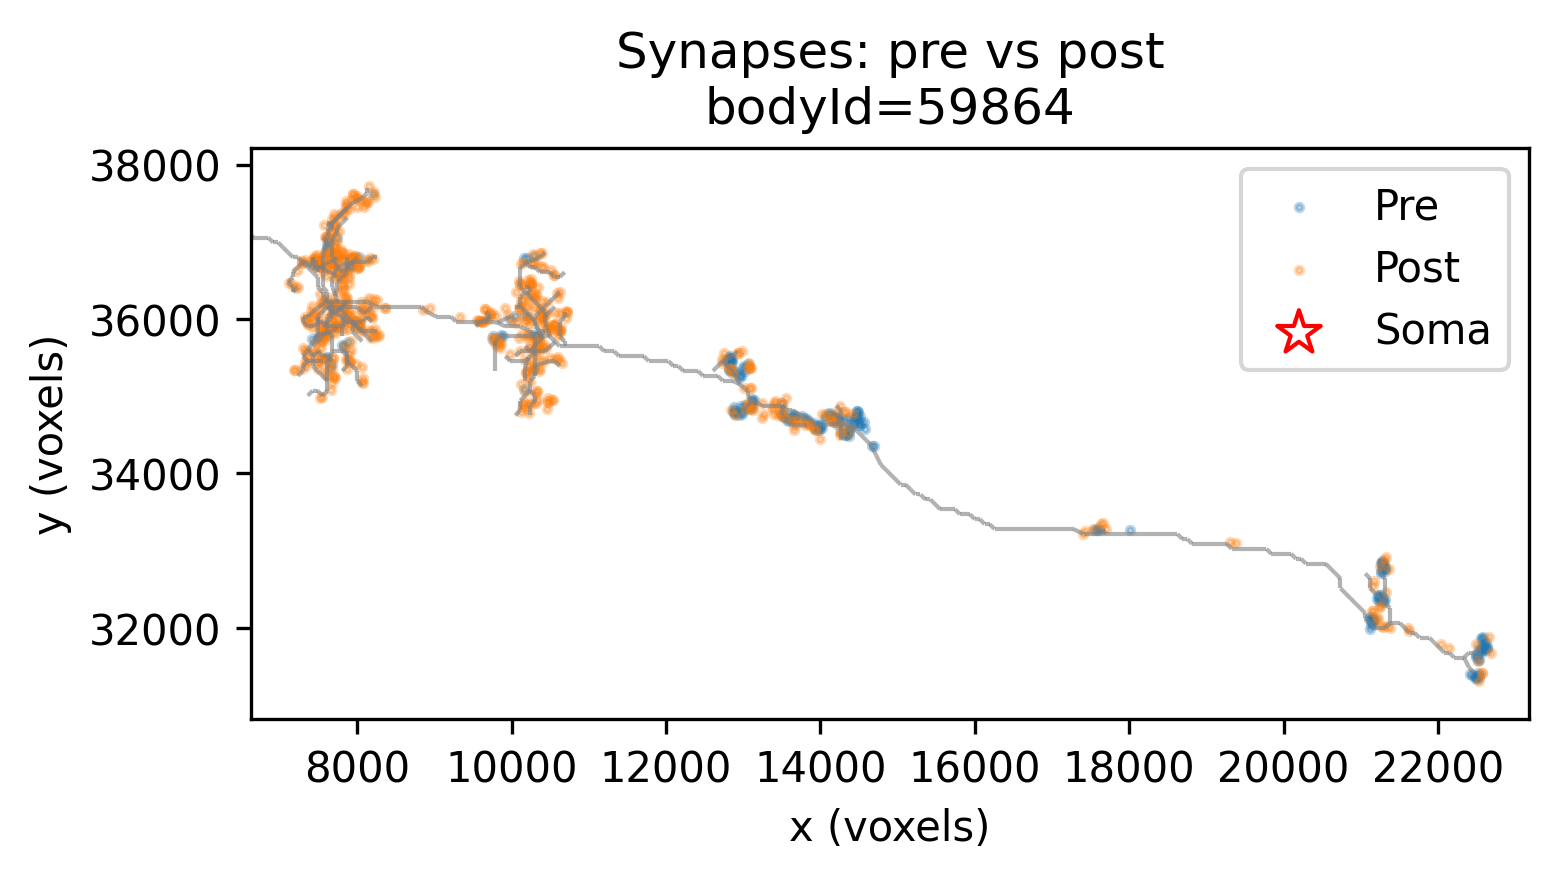

Plotting 59880 ...


  0%|          | 0/1 [00:00<?, ?it/s]

[59880] soma anchored at skeleton node 2 (scale 1, 22 from nearest node), axis=soma_oriented
[59880] clustering method used: projected_gap
[59880] cluster counts: {0: 288, 1: 17, 2: 145, 3: 71, 4: 104, 5: 100}
[59880] cluster order by d_soma_path:
             final_cluster_label   order_value  traj_coord_norm_median  \
cluster_raw                                                              
0                              0    256.000000                0.181585   
1                              1   6861.279548                0.258969   
2                              2   7528.909436                0.278605   
3                              3   9782.601219                0.430948   
4                              4  12216.812241                0.456746   
5                              5  24427.944759                0.975672   

             x_median  y_median  n_synapses  
cluster_raw                                  
0             10230.5   43998.0         288  
1             11785.0

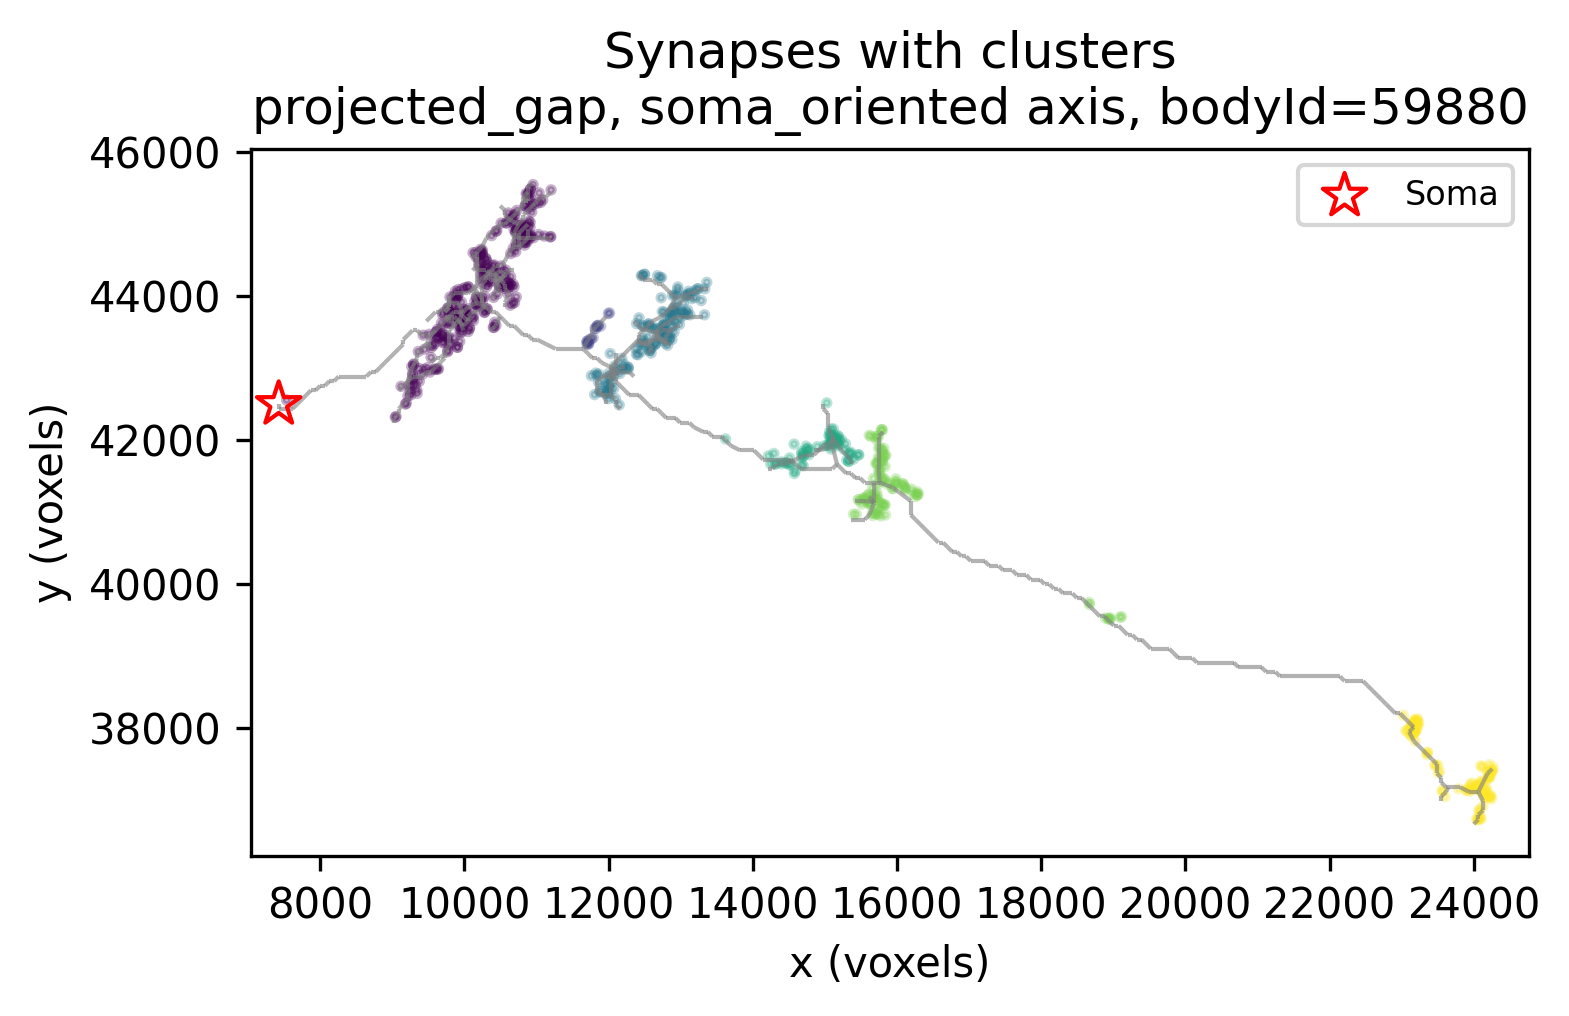

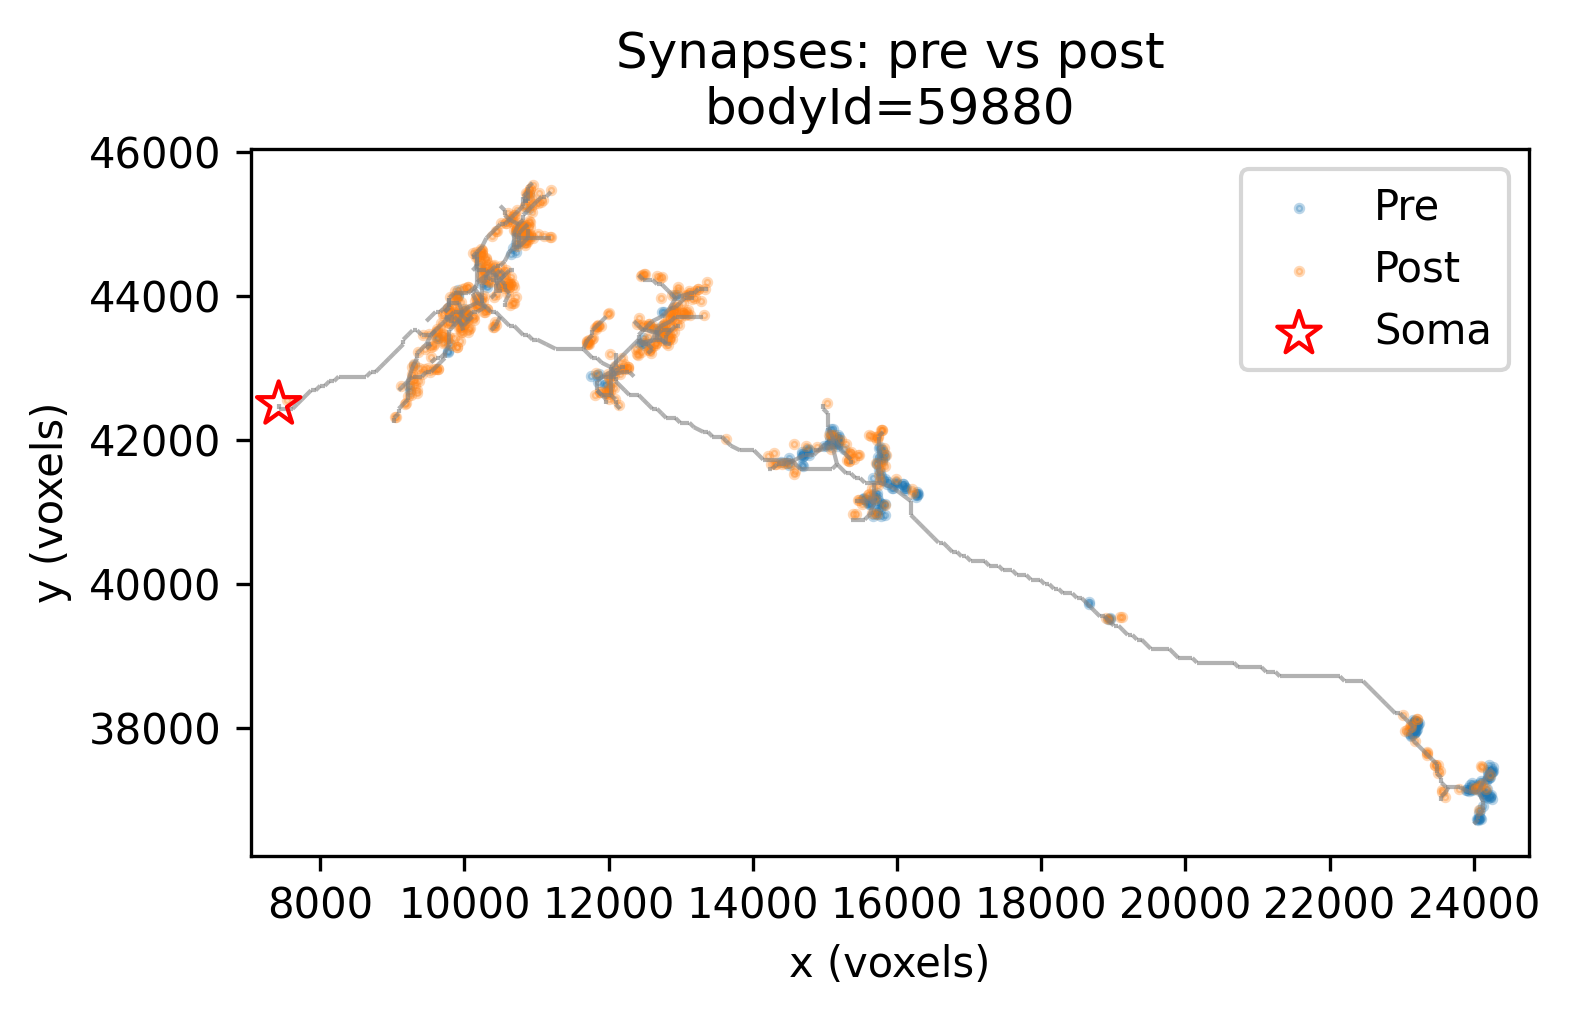

Plotting 59998 ...


  0%|          | 0/1 [00:00<?, ?it/s]

[59998] soma anchored at skeleton node 1 (scale 1, 61 from nearest node), axis=soma_oriented
[59998] clustering method used: projected_gap
[59998] cluster counts: {0: 244, 1: 31, 2: 104, 3: 162, 4: 17, 5: 102}
[59998] cluster order by d_soma_path:
             final_cluster_label   order_value  traj_coord_norm_median  \
cluster_raw                                                              
0                              0      0.000000                0.192779   
1                              1   7837.854328                0.285337   
2                              2   8390.240266                0.305447   
3                              3  10726.200992                0.455237   
4                              4  16885.364454                0.626078   
5                              5  24951.730729                0.979496   

             x_median  y_median  n_synapses  
cluster_raw                                  
0             13706.5   47963.0         244  
1             15305.0

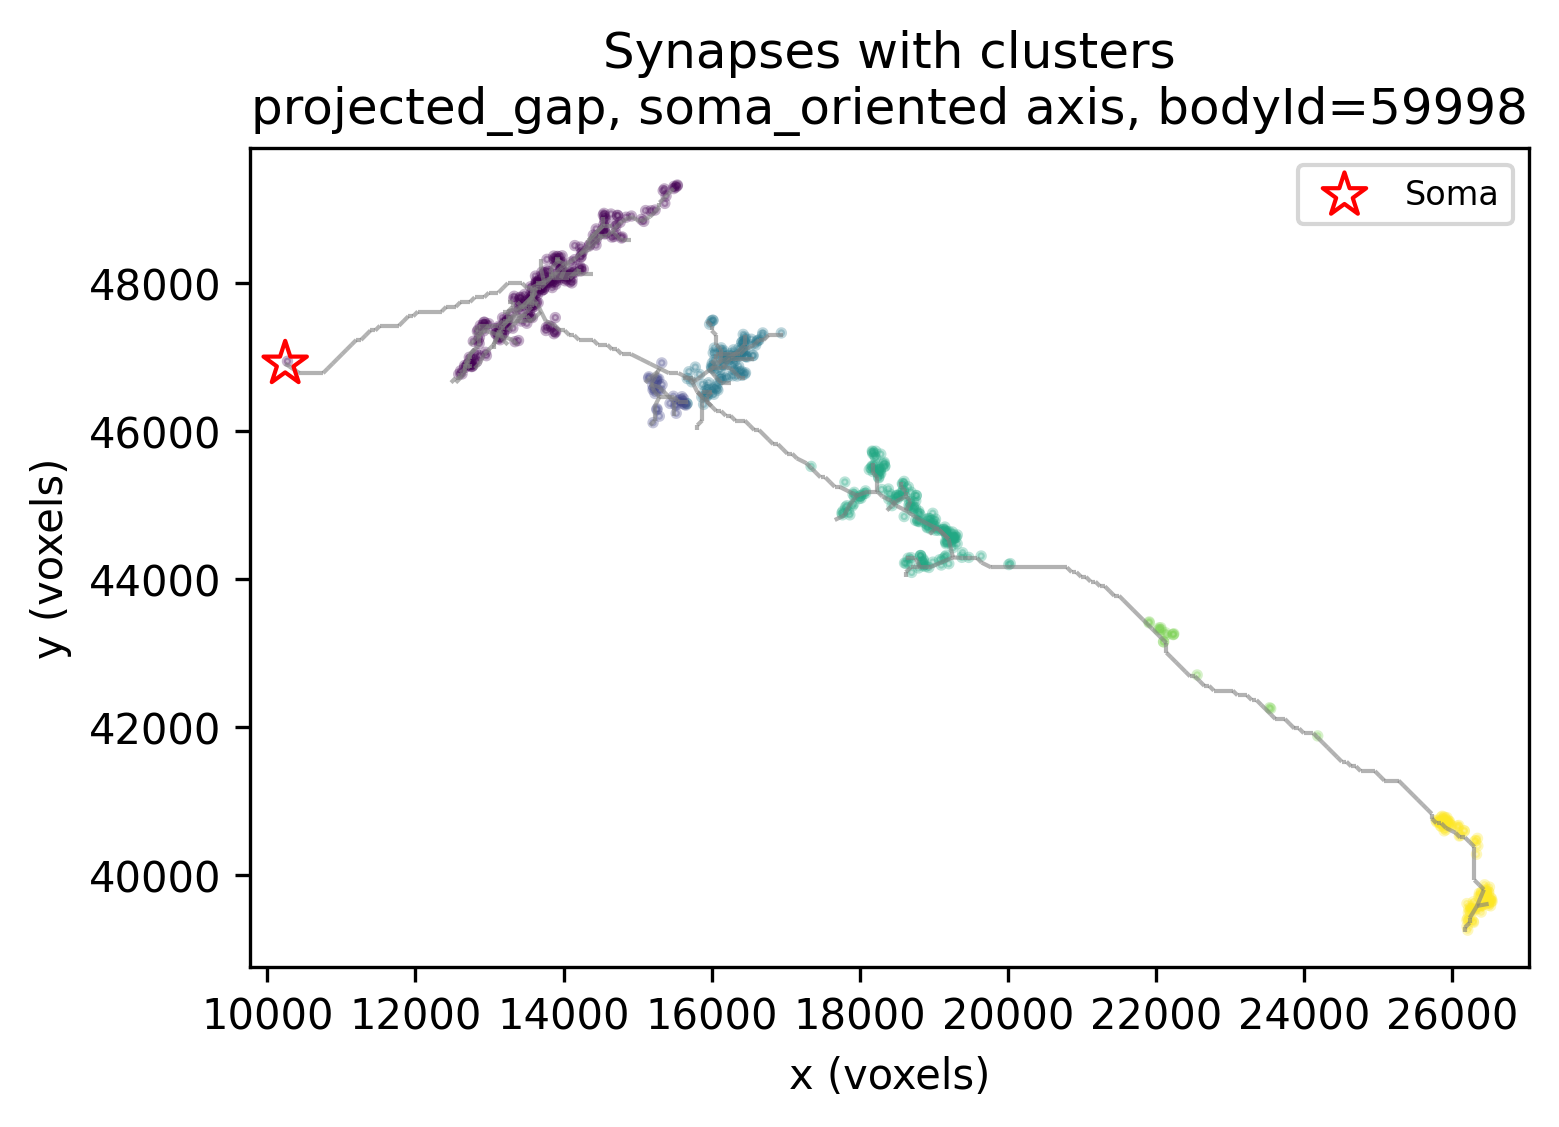

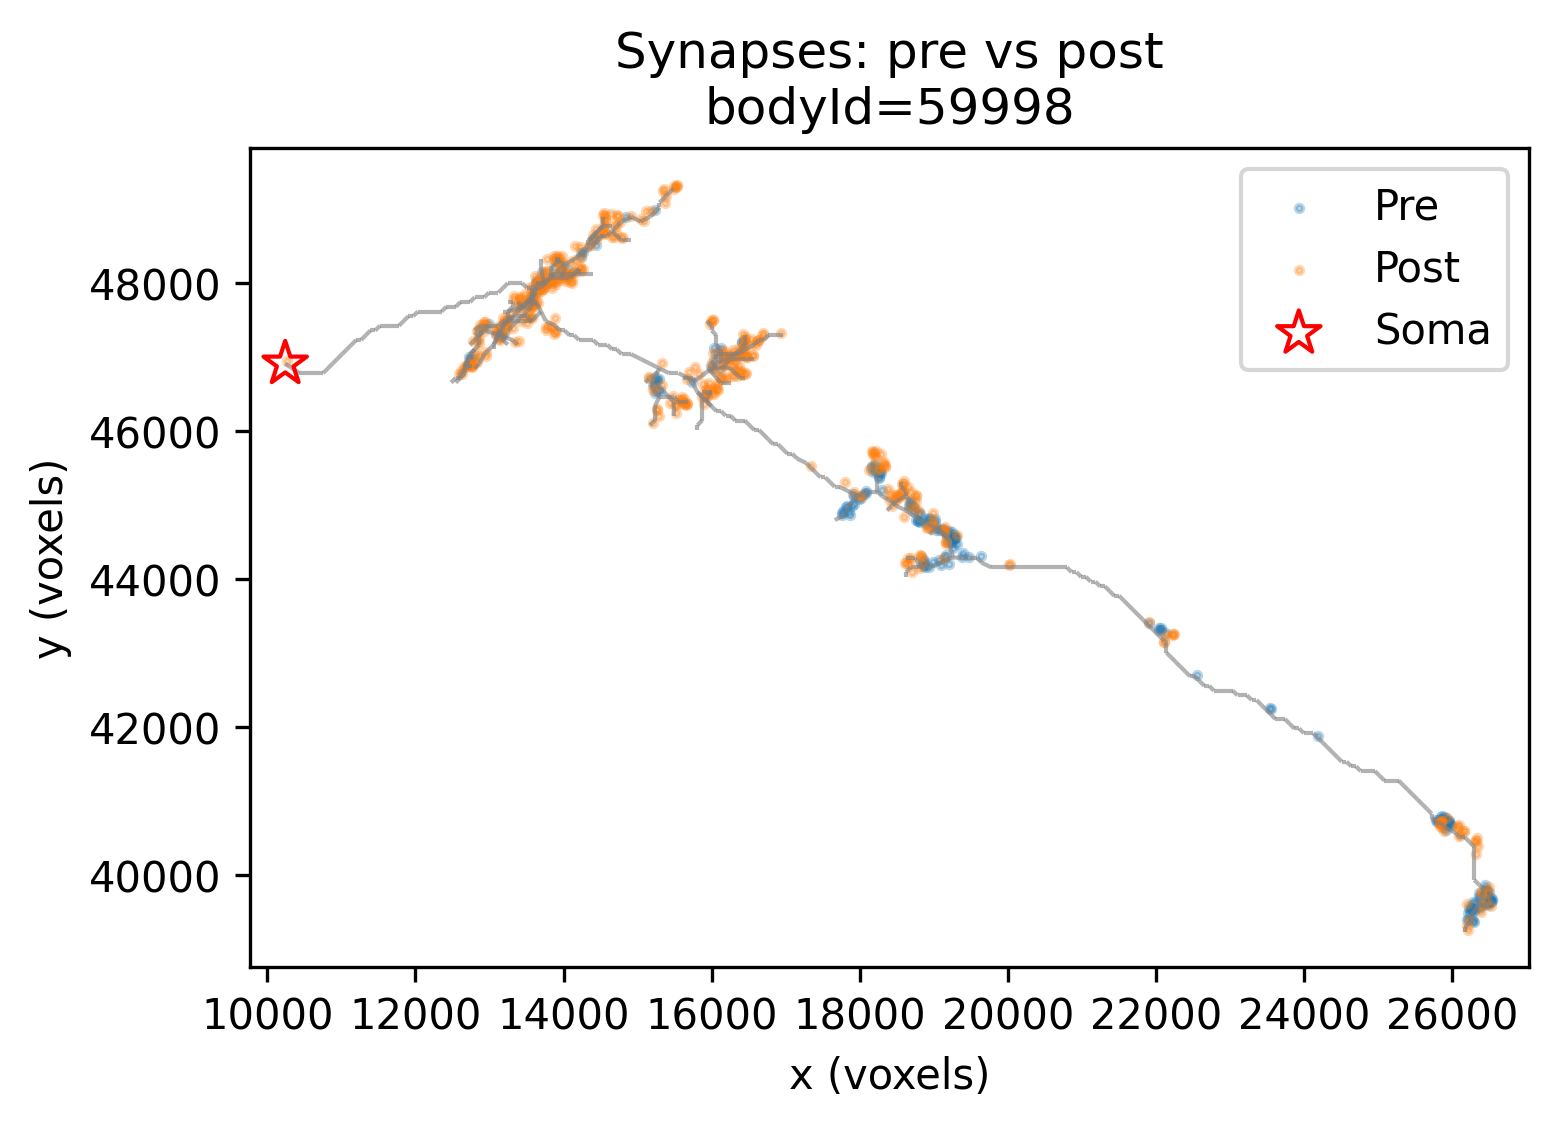

require_soma: kept 12 of 12 neurons (0 had no somaLocation, 0 could not be anchored, 0 failed for other reasons).
12 of 12 neurons clustered


In [112]:
out = plot_many_neurons_neuprint(
    neuron_ids,
    client=c,
    num_clusters=6,
    require_soma=True,                # keep only soma-anchored neurons (see the note below)
    clustering_method="projected_gap",       # "projected_gap" or "kmeans" ("projected_gap" was used for Tm3)
    gap_min_cluster_size=15,          # the gap_* settings apply to "projected_gap" only
    gap_min_gap_frac_of_median=1.5,
    gap_force_exact_num_clusters=True,
    cluster_order_metric="auto",      # d_soma_path when a soma is found
    pad=500,
    point_size=3,
    alpha=0.3,
    skeleton_alpha=0.6,
    skeleton_linewidth=1,
    show=True,                        # False runs the batch without drawing every neuron
)


n_ok = sum(1 for v in out.values() if v is not None)
print(f"{n_ok} of {len(neuron_ids)} neurons clustered")

**About `require_soma=True`.** A missing `somaLocation` usually means the cell body was cut off at the edge of the imaged volume, which depends on where the neuron sits in the tissue. So this filter is not a random subsample, and dropping many neurons may bias which columns are kept. Check how many were skipped. If it is a lot and you would rather keep them, set `require_soma=False` and use the `soma_source` column (below) to exclude them only from analyses that compare cluster numbers across neurons.

### Which neurons had a soma, and are the clusters numbered from proximal to distal?

In [74]:
rows = []

for bid, df in out.items():
    if df is None:
        rows.append({"bodyId": bid, "status": "failed"})
        continue

    medians = df.groupby("cluster")["d_soma_path"].median().sort_index().to_numpy()
    monotonic = len(medians) > 1 and bool(np.all(np.diff(medians) > 0))

    rows.append({
        "bodyId": bid,
        "status": "ok",
        "soma_source": df["soma_source"].iloc[0],
        "soma_scale": df["soma_scale"].iloc[0],
        "soma_gap": df["soma_skeleton_gap"].iloc[0],
        "traj_anchor": df["traj_anchor"].iloc[0],
        "n_clusters": df["cluster"].nunique(),
        "labels_monotonic_in_soma_dist": monotonic,
    })

qc = pd.DataFrame(rows)

print(qc["status"].value_counts().to_dict())

if "soma_source" in qc.columns:
    print(qc["soma_source"].value_counts().to_dict())
    print("scale factors used:", qc["soma_scale"].dropna().unique())
    print("worst soma-to-skeleton gap:", qc["soma_gap"].max())
    print(qc["labels_monotonic_in_soma_dist"].value_counts().to_dict())

qc.head(20)

{'ok': 100}
{'somaLocation': 100}
scale factors used: [1.]
worst soma-to-skeleton gap: 214.2755235672054
{True: 98, False: 2}


,bodyId,status,soma_source,soma_scale,soma_gap,traj_anchor,n_clusters,labels_monotonic_in_soma_dist
0,24579,ok,somaLocation,1.0,53.525695,soma_oriented,4,True
1,39810,ok,somaLocation,1.0,34.000000,soma_oriented,4,True
2,40611,ok,somaLocation,1.0,46.065171,soma_oriented,4,True
3,41059,ok,somaLocation,1.0,120.233107,soma_oriented,4,True
4,41188,ok,somaLocation,1.0,96.124919,soma_oriented,4,True
5,41531,ok,somaLocation,1.0,130.462969,soma_oriented,4,True
6,41813,ok,somaLocation,1.0,149.859634,soma_oriented,4,True
7,41816,ok,somaLocation,1.0,208.674388,soma_oriented,4,True
8,42035,ok,somaLocation,1.0,46.216880,soma_oriented,4,True
9,42133,ok,somaLocation,1.0,122.214702,soma_oriented,4,True


In [75]:
soma_lookup = fetch_soma_locations_neuprint(neuron_ids, client=c)
no_soma = [bid for bid, xyz in soma_lookup.items() if xyz is None]
print(len(no_soma), "neurons without a somaLocation:", no_soma)

0 neurons without a somaLocation: []


In [76]:
from collections import Counter

print(len(neuron_ids), "ids,", len(set(neuron_ids)), "unique")
print("repeated:", [bid for bid, n in Counter(neuron_ids).items() if n > 1])

100 ids, 100 unique
repeated: []


## 7. Export synapse counts

Pre and post synapse counts per cluster per neuron, one row per neuron and cluster.

In [100]:
def make_df_counts_from_conn_by_neuron(conn_by_neuron, expected_clusters=None, keep_column_axis_name=True):
    """
    Pre and post synapse counts per cluster per neuron, from the output of
    plot_many_neurons_neuprint. Returns a table with columns bodyId, cluster,
    pre, post.

    
    expected_clusters    e.g. range(4) adds rows with 0 counts for clusters a
                         neuron does not have; None keeps only clusters present.
    keep_column_axis_name  True names the column axis "structure".
    """
    all_counts = []

    for bodyId, df in conn_by_neuron.items():
        if df is None or df.empty:
            print(f"[{bodyId}] Skipping: no dataframe.")
            continue
        if "cluster" not in df.columns:
            print(f"[{bodyId}] Skipping: missing 'cluster' column.")
            continue
        if "structure" not in df.columns:
            print(f"[{bodyId}] Skipping: missing 'structure' column.")
            continue

        syn_df = df[df["structure"].isin(["pre", "post"])]
        if syn_df.empty:
            print(f"[{bodyId}] Skipping: no pre/post synapses.")
            continue

        counts = syn_df.groupby(["cluster", "structure"]).size().unstack("structure", fill_value=0)
        counts = counts.reindex(columns=["pre", "post"], fill_value=0)

        if expected_clusters is not None:
            counts = counts.reindex(expected_clusters, fill_value=0)
            counts.index.name = "cluster"

        counts = counts.reset_index()
        counts.insert(0, "bodyId", bodyId)
        counts = counts.astype({"bodyId": int, "cluster": int, "pre": int, "post": int})

        all_counts.append(counts)

    if all_counts:
        df_counts = pd.concat(all_counts, ignore_index=True)
    else:
        df_counts = pd.DataFrame(columns=["bodyId", "cluster", "pre", "post"])

    df_counts = df_counts[["bodyId", "cluster", "pre", "post"]]
    df_counts = df_counts.sort_values(["bodyId", "cluster"]).reset_index(drop=True)
    df_counts.columns.name = "structure" if keep_column_axis_name else None

    return df_counts

In [101]:
df_counts = make_df_counts_from_conn_by_neuron(out, expected_clusters=range(2))
df_counts.head(12)

structure,bodyId,cluster,pre,post
0,17891,0,23,439
1,17891,1,195,210
2,18509,0,20,399
3,18509,1,176,223
4,18653,0,18,326
5,18653,1,161,214
6,18675,0,16,360
7,18675,1,169,193
8,18682,0,15,365
9,18682,1,176,223


In [102]:
out_dir = "your/path/here"
os.makedirs(out_dir, exist_ok=True)

out_path = os.path.join(out_dir, "somaanchored_100_L2_df_counts.csv")
df_counts.to_csv(out_path, index=False)
print("Saved to:", out_path)

Saved to: your/path/here/somaanchored_100_L2_df_counts.csv
